<a href="https://colab.research.google.com/github/gretelZavaleta/laberinto-inundaciones-ia/blob/main/laberinto_inundaciones_ia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Practica 2 - Cuando el camino más corto no es el mejor

## Simulación de rutas seguras ante inundaciones

**Objetivo:** Implementar y comparar algoritmos de búsqueda para encontrar rutas seguras desde una zona afectada hasta un refugio, considerando obstáculos y distintos niveles de riesgo.

**Integrantes:**
- Gretel Dairen Zavaleta Moctezuma
- Maria Tita Fregoso Arechiga
- Jesús Alexander Recaman Lara
- Henrry Misael Pech Pool


# PARTE 1 · Modelado del Terreno y Costos de Riesgo

La posición de cada celda en la simulación se expresa como `(fila, columna)` dentro de una matriz de $12 \times 16$ (superando el mínimo requerido de $10 \times 10$). El agente solo puede desplazarse de forma ortogonal (arriba, abajo, izquierda y derecha). El costo de cada transición está determinado por el nivel de inundación de la casilla de destino.

### 1. Definición de niveles de inundación y riesgo

| Nivel | Significado | Costo de entrada | Condición |
|---|---|---|---|
| **0** | Zona segura | 1 | Transitable (óptimo) |
| **1** | Inundación baja (Riesgo bajo) | 3 | Transitable con precaución |
| **2** | Inundación media (Riesgo medio) | 6 | Transitable con riesgo considerable |
| **3** | Inundación alta (Riesgo severo) | 10 | Transitable solo en emergencia |
| **4** | Zona bloqueada | $\infty$ | Intransitable (impede el paso) |

In [1]:
"""Modelo del terreno inundado para la simulación de rutas seguras.

Coordenadas: (fila, columna). Movimientos: arriba, abajo, izquierda y derecha.
El costo de una transición es el costo de ENTRAR a la casilla de destino.
"""

FILAS = 12
COLUMNAS = 16
INICIO = (6, 1)
REFUGIO = (6, 14)

# 0=segura, 1=riesgo bajo, 2=medio, 3=alto, 4=bloqueada.
COSTOS = {0: 1, 1: 3, 2: 6, 3: 10}
BLOQUEADO = 4




2. Construcción del terreno
Generamos una cuadrícula fija de 12 × 16. Se aplican regiones de riesgo de menor a mayor nivel para simular una zona inundada. Después agregamos obstáculos. Se reservan puntos transitables para el inicio y el refugio.

In [2]:
def crear_terreno():
    """Crea un escenario reproducible con zonas seguras y varios riesgos."""
    terreno = [[0 for _ in range(COLUMNAS)] for _ in range(FILAS)]

    # Orden importante: de zonas de menor a mayor riesgo.
    for fila in range(2, 10):
        for columna in range(2, 15):
            terreno[fila][columna] = 1

    for fila in range(3, 9):
        for columna in range(3, 14):
            terreno[fila][columna] = 2

    for fila in range(5, 8):
        for columna in range(6, 11):
            terreno[fila][columna] = 3

    # Celdas intransitables, incluso si antes tenían un nivel de riesgo.
    obstaculos = [(4, 4), (4, 5), (4, 6), (3, 8), (3, 9),
                  (7, 11), (8, 11), (8, 12)]
    for fila, columna in obstaculos:
        terreno[fila][columna] = BLOQUEADO

    # El inicio y el refugio deben ser transitables.
    terreno[INICIO[0]][INICIO[1]] = 0
    terreno[REFUGIO[0]][REFUGIO[1]] = 0
    return terreno

3. Funciones que usarán los algoritmos
- es_transitable evita salirse de la matriz y atravesar zonas bloqueadas.
- obtener_vecinos permite desplazamientos ortogonales, sin diagonales.
- costo_movimiento asigna el costo del nivel de inundación en la celda de destino.

In [3]:
def es_transitable(terreno, posicion):
    """Indica si la posición está dentro de la matriz y no está bloqueada."""
    fila, columna = posicion
    return (0 <= fila < len(terreno)
            and 0 <= columna < len(terreno[0])
            and terreno[fila][columna] != BLOQUEADO)


def obtener_vecinos(terreno, posicion):
    """Devuelve las posiciones vecinas transitables (sin diagonales)."""
    if not es_transitable(terreno, posicion):
        return []
    fila, columna = posicion
    movimientos = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    vecinos = []
    for df, dc in movimientos:
        vecino = (fila + df, columna + dc)
        if es_transitable(terreno, vecino):
            vecinos.append(vecino)
    return vecinos


def costo_movimiento(terreno, destino):
    """Retorna el costo de entrar en destino; rechaza celdas bloqueadas."""
    if not es_transitable(terreno, destino):
        raise ValueError(f"No se puede entrar en la celda {destino}.")
    return COSTOS[terreno[destino[0]][destino[1]]]

### 4. Modificar el escenario y verificar sus reglas:

modificar_terreno devuelve una copia. Así podemos ejecutar los escenarios de prueba sin sobrescribir el terreno original. validar_escenario asegura que la matriz sea rectangular, use niveles conocidos y mantenga accesibles los puntos de inicio y refugio.

In [4]:
def modificar_terreno(terreno, posicion, nuevo_nivel):
    """Retorna una COPIA con un nivel actualizado sin modificar el original."""
    if nuevo_nivel not in (0, 1, 2, 3, BLOQUEADO):
        raise ValueError("El nivel debe ser 0, 1, 2, 3 o 4.")
    fila, columna = posicion
    if not (0 <= fila < len(terreno) and 0 <= columna < len(terreno[0])):
        raise ValueError("La posición está fuera del terreno.")
    nuevo_terreno = [renglon.copy() for renglon in terreno]
    nuevo_terreno[fila][columna] = nuevo_nivel
    return nuevo_terreno


def validar_escenario(terreno, inicio, refugio):
    """Verifica dimensiones, valores y que inicio/refugio sean transitables."""
    if not terreno or not terreno[0]:
        raise ValueError("El terreno no puede estar vacío.")
    columnas = len(terreno[0])
    if any(len(fila) != columnas for fila in terreno):
        raise ValueError("Todas las filas deben tener el mismo tamaño.")
    if any(nivel not in (0, 1, 2, 3, BLOQUEADO)
           for fila in terreno for nivel in fila):
        raise ValueError("El terreno contiene niveles desconocidos.")
    if not es_transitable(terreno, inicio):
        raise ValueError("El inicio no es transitable.")
    if not es_transitable(terreno, refugio):
        raise ValueError("El refugio no es transitable.")
    return True

### 5. Funciones de visualización gráfica
Representamos visualmente el terreno mediante `matplotlib`, diferenciando con una paleta semafórica cada nivel de inundación, en gris oscuro las zonas intransitables, con un círculo azul el punto de partida y con una estrella verde el refugio.

Dimensiones del escenario base: 12 × 16
Coordenada de Inicio: (6, 1) | Coordenada de Refugio: (6, 14)


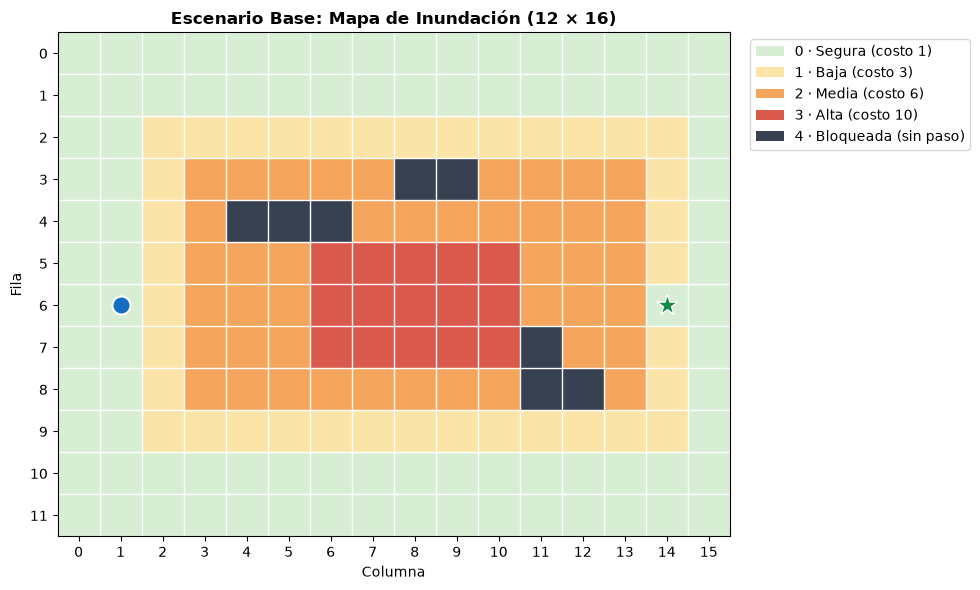

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

COLORES_MAPA = ["#D7EED4", "#FBE4A8", "#F6A55C", "#D9594C", "#374151"]
CMAP_TERRENO = ListedColormap(COLORES_MAPA)

def visualizar_terreno(terreno, inicio=INICIO, refugio=REFUGIO, titulo="Mapa de inundación"):
    """Dibuja el terreno base, el inicio y el refugio."""
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.imshow(terreno, cmap=CMAP_TERRENO, vmin=-0.5, vmax=4.5, interpolation="nearest")
    filas, columnas = len(terreno), len(terreno[0])
    ax.set_xticks(range(columnas))
    ax.set_yticks(range(filas))
    ax.set_xticks([n - 0.5 for n in range(columnas + 1)], minor=True)
    ax.set_yticks([n - 0.5 for n in range(filas + 1)], minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.scatter(inicio[1], inicio[0], s=170, marker="o", c="#146FC4",
               edgecolors="white", linewidths=1.5, zorder=3, label="Inicio")
    ax.scatter(refugio[1], refugio[0], s=250, marker="*", c="#138A48",
               edgecolors="white", linewidths=1, zorder=3, label="Refugio")
    ax.set_xlabel("Columna")
    ax.set_ylabel("Fila")
    ax.set_title(titulo, fontweight="bold")
    leyenda = [Patch(facecolor=COLORES_MAPA[i], label=texto) for i, texto in enumerate([
        "0 · Segura (costo 1)", "1 · Baja (costo 3)",
        "2 · Media (costo 6)", "3 · Alta (costo 10)",
        "4 · Bloqueada (sin paso)"])]
    ax.legend(handles=leyenda, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


def visualizar_ruta(terreno, resultado, inicio=INICIO, refugio=REFUGIO, titulo=None):
    """Dibuja el terreno y superpone la trayectoria encontrada por un algoritmo."""
    ruta = resultado["ruta"]
    if titulo is None:
        if ruta:
            titulo = (f"{resultado['algoritmo']} — {resultado['pasos']} pasos | "
                      f"Costo: {resultado['costo']} | Expandidos: {resultado['expandidos']}")
        else:
            titulo = f"{resultado['algoritmo']} — SIN RUTA DISPONIBLE (Expandidos: {resultado['expandidos']})"

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(terreno, cmap=CMAP_TERRENO, vmin=-0.5, vmax=4.5, interpolation="nearest")

    if ruta:
        filas = [pos[0] for pos in ruta]
        columnas = [pos[1] for pos in ruta]
        ax.plot(columnas, filas, color="#1D4ED8", linewidth=3, marker="o", markersize=5, label="Ruta", zorder=4)

    ax.scatter(inicio[1], inicio[0], color="#146FC4", edgecolors="white", linewidths=1.5, s=160, label="Inicio", zorder=5)
    ax.scatter(refugio[1], refugio[0], color="#138A48", edgecolors="white", linewidths=1, marker="*", s=260, label="Refugio", zorder=5)

    filas_t, cols_t = len(terreno), len(terreno[0])
    ax.set_xticks(range(cols_t))
    ax.set_yticks(range(filas_t))
    ax.set_xticks([n - 0.5 for n in range(cols_t + 1)], minor=True)
    ax.set_yticks([n - 0.5 for n in range(filas_t + 1)], minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_xlabel("Columna")
    ax.set_ylabel("Fila")
    ax.set_title(titulo, fontweight="bold")
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


terreno = crear_terreno()
validar_escenario(terreno, INICIO, REFUGIO)
print(f"Dimensiones del escenario base: {len(terreno)} × {len(terreno[0])}")
print("Coordenada de Inicio:", INICIO, "| Coordenada de Refugio:", REFUGIO)
visualizar_terreno(terreno, INICIO, REFUGIO, "Escenario Base: Mapa de Inundación (12 × 16)")

---
# PARTE 2 · Estrategias de Búsqueda y Justificación del Riesgo

Implementamos y comparamos tres estrategias de búsqueda con distintas perspectivas operativas:

| Algoritmo | Perspectiva / Qué minimiza | ¿Considera el riesgo del terreno? | Uso de Heurística |
|---|---|---|---|
| **BFS (Búsqueda en Anchura)** | Cantidad de pasos (distancia geométrica en bordes) | **No** (solo distingue entre transitable y bloqueado) | No |
| **Dijkstra (Costo Uniforme)** | Costo total acumulado (pasos + riesgo de inundación) | **Sí** | No ($h(n) = 0$) |
| **A* (A-Estrella)** | Costo total acumulado guiado hacia el objetivo ($f = g + h$) | **Sí** | Sí (Distancia de Manhattan) |

### ¿Cómo incorpora el sistema la información del riesgo y cómo decide cuál ruta es mejor?
Para responder a la pregunta planteada:
> *"Si dos rutas llegan al mismo refugio, pero una es más corta y la otra atraviesa zonas de mayor riesgo, ¿cómo determina su sistema cuál es la mejor?"*

Nuestro sistema modela el problema mediante una **función de costo de transición parametrizada** `costo_paso(terreno, destino, peso_riesgo)`:
$$c(u, v) = 1 + w_{\text{riesgo}} \cdot (\text{COSTO}[\text{nivel}(v)] - 1)$$

Con el parámetro estándar `peso_riesgo = 1.0`, entrar a una celda segura cuesta $1$, mientras que entrar a una celda de inundación alta cuesta $10$. Para cualquier ruta $R = \langle n_0, n_1, \dots, n_k \rangle$, el costo total es la suma de los costos de entrada a cada celda sucesiva:
$$\text{Costo}(R) = \sum_{i=1}^{k} c(n_{i-1}, n_i)$$

* **En BFS:** El algoritmo utiliza una cola FIFO (`deque`) y explora por capas de profundidad. Por diseño, ignora la función de costo al tomar decisiones y elige siempre la ruta con menor número de aristas $k$, aunque atraviese el centro inundado y acumule un riesgo altísimo.
* **En Dijkstra y A\*:** Ambos mantienen un diccionario de costos acumulados reales $g(n)$ y utilizan una **cola de prioridad (min-heap)**. Si la Ruta A tiene **13 pasos** cruzando agua profunda ($\text{Costo} = 90$) y la Ruta B tiene **23 pasos** rodeando por tierra firme ($\text{Costo} = 23$), la cola de prioridad extraerá y expandirá primero los nodos de la Ruta B porque $23 < 90$. Así, el sistema demuestra algorítmicamente que **la ruta más conveniente es la que minimiza el riesgo acumulado y no simplemente el número de pasos**.
* **Ventaja de A\* sobre Dijkstra:** Mientras Dijkstra expande nodos en todas direcciones por igual según su costo $g(n)$, **A\*** prioriza mediante $f(n) = g(n) + h(n)$, donde $h(n) = \vert{}f_{\text{actual}} - f_{\text{refugio}}\vert{} + \vert{}c_{\text{actual}} - c_{\text{refugio}}\vert{}$ es la **Distancia de Manhattan**. Como el costo mínimo de pisar cualquier celda es $1$, esta heurística es **admisible y consistente** (nunca sobreestima el costo real), garantizando encontrar exactamente el mismo camino óptimo que Dijkstra pero realizando mucho menos trabajo (menos nodos expandidos).


In [6]:
import heapq
import time
from collections import deque

INF = float("inf")


def costo_paso(terreno, destino, peso_riesgo=1.0):
    """Costo de entrar a 'destino'. Con peso_riesgo=1 es exactamente COSTOS[nivel];
    con peso_riesgo=0 todos los pasos cuestan 1 (se ignora el riesgo)."""
    return 1.0 + peso_riesgo * (costo_movimiento(terreno, destino) - 1)


def costo_ruta(terreno, ruta, peso_riesgo=1.0):
    """Suma el costo de entrada de cada celda de la ruta (excluyendo la celda inicial)."""
    return sum(costo_paso(terreno, n, peso_riesgo) for n in ruta[1:])


def validar_ruta_obtenida(terreno, ruta, inicio, refugio):
    """Comprueba que la ruta obtenida respete todas las condiciones del escenario."""
    if not ruta:  # None o lista vacía (antes: IndexError con ruta == [])
        return False
    if ruta[0] != inicio or ruta[-1] != refugio:
        return False
    for i, celda in enumerate(ruta):
        if not es_transitable(terreno, celda):
            return False
        if i > 0:
            df = abs(ruta[i][0] - ruta[i - 1][0])
            dc = abs(ruta[i][1] - ruta[i - 1][1])
            if df + dc != 1:  # Solo pasos ortogonales unitarios
                return False
    return True


def reconstruir_ruta(padres, fin):
    ruta, nodo = [], fin
    while nodo is not None:
        ruta.append(nodo)
        nodo = padres[nodo]
    return ruta[::-1]


def _resultado(nombre, terreno, ruta, expandidos, t0, peso_riesgo, inicio=INICIO, refugio=REFUGIO):
    es_valida = validar_ruta_obtenida(terreno, ruta, inicio, refugio) if ruta else False
    return {
        "algoritmo": nombre,
        "ruta": ruta,
        "valida": es_valida,
        "costo": costo_ruta(terreno, ruta, peso_riesgo) if ruta else None,
        "pasos": len(ruta) - 1 if ruta else None,
        "expandidos": expandidos,
        "tiempo_ms": round((time.perf_counter() - t0) * 1000, 4),
        "nivel_max": max(terreno[f][c] for f, c in ruta) if ruta else None,
    }


def _extremos_validos(terreno, inicio, refugio):
    return es_transitable(terreno, inicio) and es_transitable(terreno, refugio)


def bfs(terreno, inicio=INICIO, refugio=REFUGIO, peso_riesgo=1.0):
    """Búsqueda en Anchura: encuentra la ruta con menor número de pasos (ignora el riesgo al decidir)."""
    t0 = time.perf_counter()
    if not _extremos_validos(terreno, inicio, refugio):
        return _resultado("BFS", terreno, None, 0, t0, peso_riesgo, inicio, refugio)
    if inicio == refugio:
        return _resultado("BFS", terreno, [inicio], 1, t0, peso_riesgo, inicio, refugio)

    padres = {inicio: None}
    cola = deque([inicio])
    expandidos = 0
    while cola:
        actual = cola.popleft()
        expandidos += 1
        if actual == refugio:
            ruta = reconstruir_ruta(padres, actual)
            return _resultado("BFS", terreno, ruta, expandidos, t0, peso_riesgo, inicio, refugio)
        for vecino in obtener_vecinos(terreno, actual):
            if vecino not in padres:
                padres[vecino] = actual
                cola.append(vecino)
    return _resultado("BFS", terreno, None, expandidos, t0, peso_riesgo, inicio, refugio)


def dijkstra(terreno, inicio=INICIO, refugio=REFUGIO, peso_riesgo=1.0):
    """Algoritmo de Dijkstra: encuentra la ruta de menor costo acumulado (pasos + riesgo)."""
    t0 = time.perf_counter()
    if peso_riesgo < 0:
        raise ValueError("peso_riesgo debe ser >= 0")
    if not _extremos_validos(terreno, inicio, refugio):
        return _resultado("Dijkstra", terreno, None, 0, t0, peso_riesgo, inicio, refugio)

    dist = {inicio: 0.0}
    padres = {inicio: None}
    cerrados = set()
    desempate = 0
    heap = [(0.0, desempate, inicio)]
    expandidos = 0

    while heap:
        d, _, actual = heapq.heappop(heap)
        if actual in cerrados:
            continue
        cerrados.add(actual)
        expandidos += 1
        if actual == refugio:
            ruta = reconstruir_ruta(padres, actual)
            return _resultado("Dijkstra", terreno, ruta, expandidos, t0, peso_riesgo, inicio, refugio)
        for vecino in obtener_vecinos(terreno, actual):
            if vecino in cerrados:
                continue
            nuevo = d + costo_paso(terreno, vecino, peso_riesgo)
            if nuevo < dist.get(vecino, INF):
                dist[vecino] = nuevo
                padres[vecino] = actual
                desempate += 1
                heapq.heappush(heap, (nuevo, desempate, vecino))
    return _resultado("Dijkstra", terreno, None, expandidos, t0, peso_riesgo, inicio, refugio)


def heuristica(nodo, objetivo):
    """Calcula la distancia de Manhattan entre dos coordenadas ortogonales."""
    return abs(nodo[0] - objetivo[0]) + abs(nodo[1] - objetivo[1])


def a_estrella(terreno, inicio=INICIO, refugio=REFUGIO, peso_riesgo=1.0):
    """Algoritmo A*: encuentra la ruta de menor costo acumulado guiado por heurística (f = g + h)."""
    t0 = time.perf_counter()
    if peso_riesgo < 0:
        raise ValueError("peso_riesgo debe ser >= 0")
    if not _extremos_validos(terreno, inicio, refugio):
        return _resultado("A*", terreno, None, 0, t0, peso_riesgo, inicio, refugio)

    g_score = {inicio: 0.0}
    padres = {inicio: None}
    cerrados = set()
    desempate = 0
    heap = [(heuristica(inicio, refugio), desempate, inicio)]
    expandidos = 0

    while heap:
        _, _, actual = heapq.heappop(heap)
        if actual in cerrados:
            continue
        cerrados.add(actual)
        expandidos += 1
        if actual == refugio:
            ruta = reconstruir_ruta(padres, actual)
            return _resultado("A*", terreno, ruta, expandidos, t0, peso_riesgo, inicio, refugio)
        for vecino in obtener_vecinos(terreno, actual):
            if vecino in cerrados:
                continue
            nuevo_g = g_score[actual] + costo_paso(terreno, vecino, peso_riesgo)
            if nuevo_g < g_score.get(vecino, INF):
                g_score[vecino] = nuevo_g
                padres[vecino] = actual
                desempate += 1
                f_score = nuevo_g + heuristica(vecino, refugio)
                heapq.heappush(heap, (f_score, desempate, vecino))
    return _resultado("A*", terreno, None, expandidos, t0, peso_riesgo, inicio, refugio)


def comparar_estrategias(terreno_prueba, inicio=INICIO, refugio=REFUGIO, peso_riesgo=1.0, mostrar_graficas=True):
    """Ejecuta BFS, Dijkstra y A* en el mismo escenario, imprime tabla comparativa y grafica."""
    resultados = [
        bfs(terreno_prueba, inicio, refugio, peso_riesgo),
        dijkstra(terreno_prueba, inicio, refugio, peso_riesgo),
        a_estrella(terreno_prueba, inicio, refugio, peso_riesgo)
    ]
    print(f"{'Algoritmo':<10} | {'¿Ruta válida?':<14} | {'Pasos':<6} | {'Costo Total':<12} | {'Nodos Expandidos':<17} | {'Riesgo Máx':<10} | {'Tiempo (ms)':<11}")
    print("-" * 96)
    for r in resultados:
        val_str = "Sí" if r["valida"] else "No (Sin ruta)"
        pasos_str = str(r["pasos"]) if r["pasos"] is not None else "N/A"
        costo_str = f"{r['costo']:.1f}" if r["costo"] is not None else "N/A"
        niv_str = str(r["nivel_max"]) if r["nivel_max"] is not None else "N/A"
        print(f"{r['algoritmo']:<10} | {val_str:<14} | {pasos_str:<6} | {costo_str:<12} | {r['expandidos']:<17} | {niv_str:<10} | {r['tiempo_ms']:<11}")

    if mostrar_graficas:
        for r in resultados:
            visualizar_ruta(terreno_prueba, r, inicio, refugio)
    return resultados

---
# PARTE 3 · Batería de Pruebas de Escenarios

A continuación sometemos nuestra implementación a los **6 escenarios de prueba requeridos** sobre matrices de $12 \times 16$:

### Prueba 1 y Prueba 5: Ruta disponible hasta el refugio y "Cuando el camino más corto no es el más conveniente"
En nuestro escenario base existe conexión directa entre `(6, 1)` y `(6, 14)`. Evaluamos cómo **BFS** elige el camino directo de **13 pasos** atravesando el centro severamente inundado (Nivel 3, acumulando un **costo de 90.0**), mientras que **Dijkstra** y **A\*** deciden rodear toda la zona inundada por el borde inferior seguro (Nivel 0), tomando **23 pasos** pero reduciendo el **costo total a solo 23.0**. Además, se observa cómo **A\*** realiza casi la mitad de trabajo que Dijkstra (**80 nodos expandidos vs. 146**).

=== PRUEBA 1 Y 5: ESCENARIO BASE (CAMINO CORTO PELIGROSO VS. LARGO SEGURO) ===
Algoritmo  | ¿Ruta válida?  | Pasos  | Costo Total  | Nodos Expandidos  | Riesgo Máx | Tiempo (ms)
------------------------------------------------------------------------------------------------
BFS        | Sí             | 13     | 90.0         | 136               | 3          | 0.623      
Dijkstra   | Sí             | 23     | 23.0         | 146               | 0          | 1.3141     
A*         | Sí             | 23     | 23.0         | 80                | 0          | 0.8684     


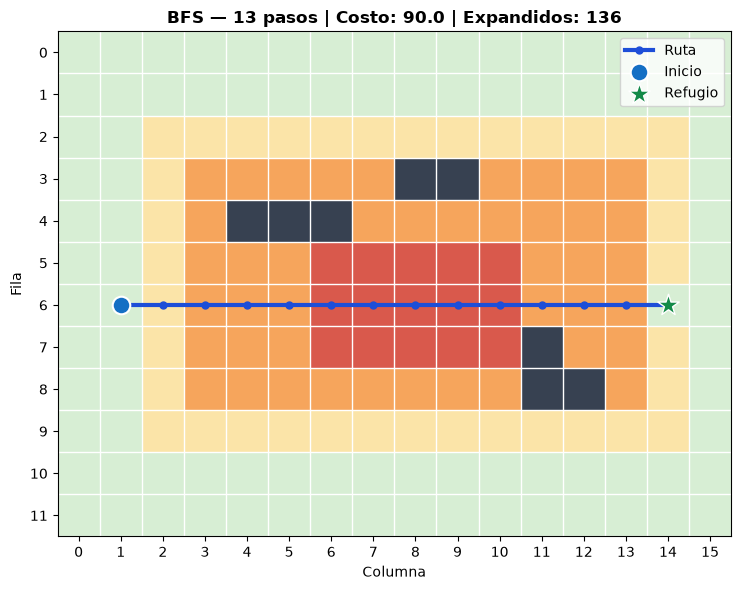

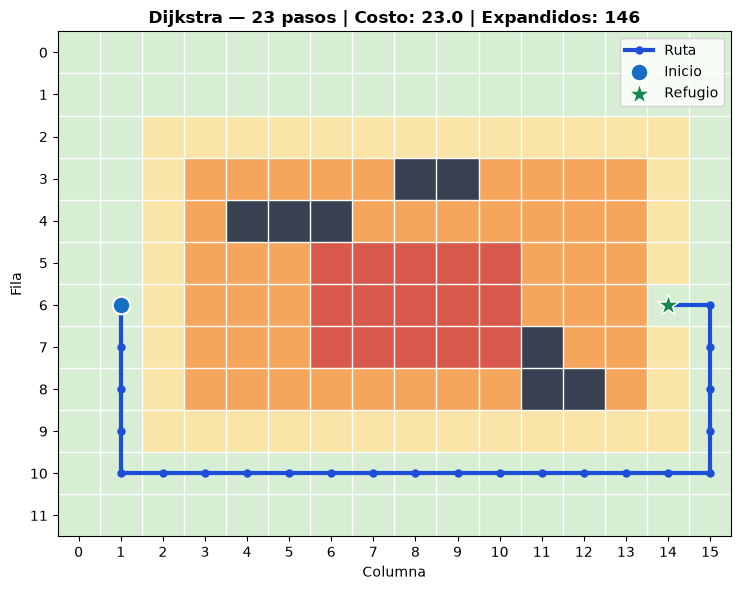

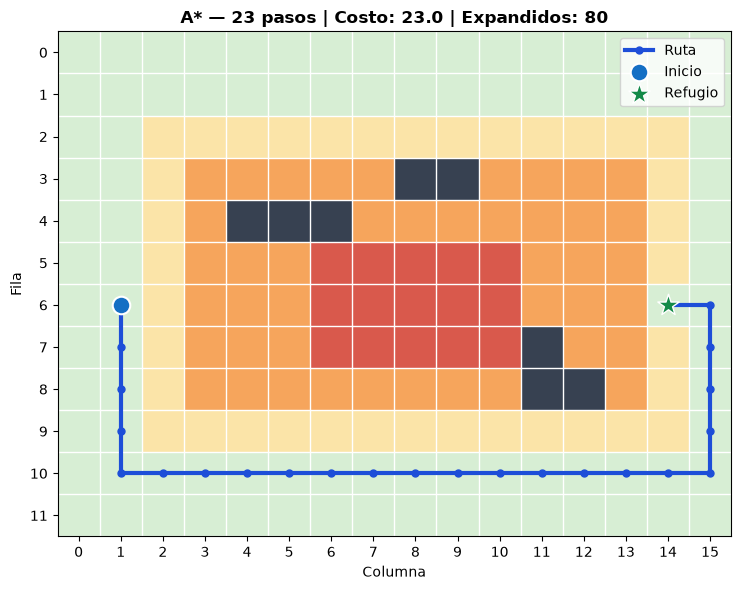

In [7]:
print("=== PRUEBA 1 Y 5: ESCENARIO BASE (CAMINO CORTO PELIGROSO VS. LARGO SEGURO) ===")
res_base = comparar_estrategias(terreno)

### Prueba 2: Se bloquea una zona que anteriormente formaba parte de la ruta
En la Prueba 1 la ruta óptima de **Dijkstra y A\*** recorre el **corredor seguro inferior** (filas 10 y 11). Para que la prueba realmente cambie su decisión, bloqueamos `(10, 7)` —celda que **pertenece a esa ruta**— y su vecina `(11, 7)`, cerrando el corredor inferior en esa columna. También se bloquea `(6, 8)`, que forma parte del camino central de BFS.

La celda bloqueada se toma **directamente de la ruta obtenida en la Prueba 1** (no se escribe "a mano") y se comprueba con `assert` que la nueva ruta (a) es válida, (b) no pisa ninguna celda bloqueada y (c) es distinta y más cara que la anterior: el sistema reencamina por el corredor superior.

> Nota del equipo: una versión previa de esta prueba bloqueaba celdas del corredor *superior*, que ninguna de las rutas de Dijkstra/A\* usaba, por lo que su ruta no cambiaba. Se corrigió para que la prueba compruebe lo que dice comprobar.

=== PRUEBA 2: BLOQUEO DE ZONAS QUE FORMABAN PARTE DE LAS RUTAS ANTERIORES ===
Algoritmo  | ¿Ruta válida?  | Pasos  | Costo Total  | Nodos Expandidos  | Riesgo Máx | Tiempo (ms)
------------------------------------------------------------------------------------------------
BFS        | Sí             | 15     | 101.0        | 147               | 3          | 0.4151     
Dijkstra   | Sí             | 25     | 25.0         | 137               | 0          | 0.6443     
A*         | Sí             | 25     | 25.0         | 97                | 0          | 0.5179     


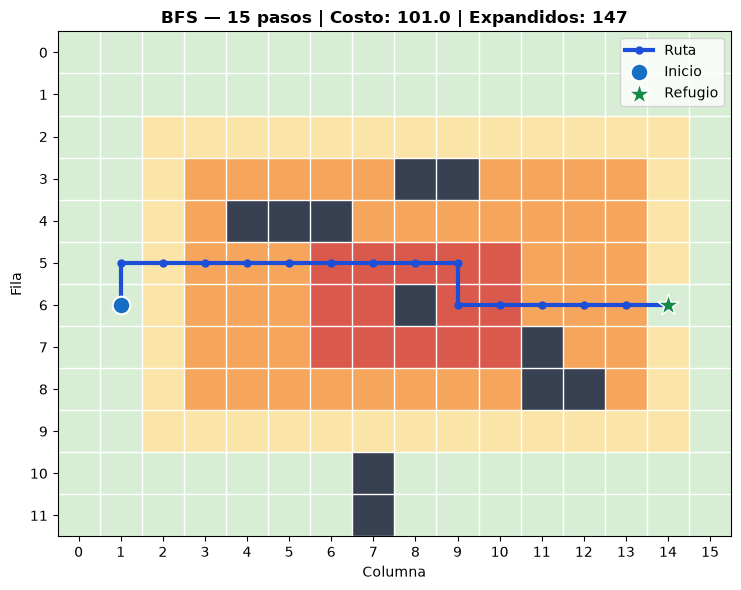

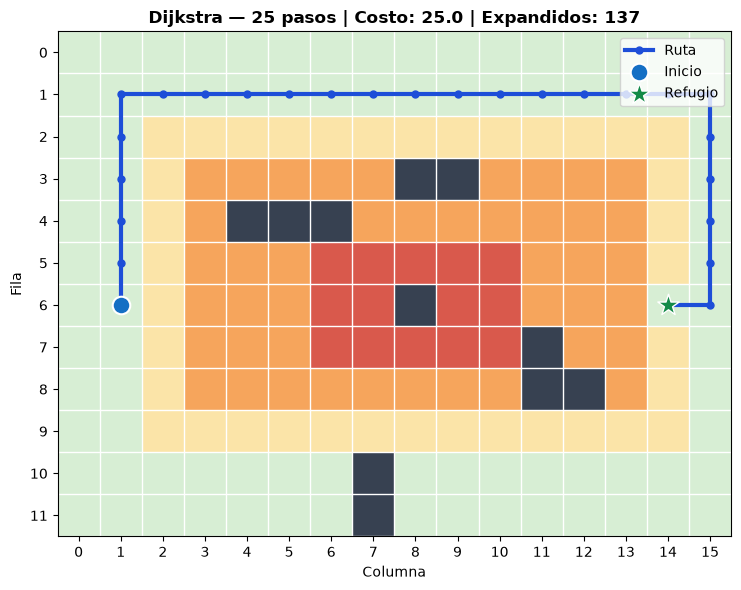

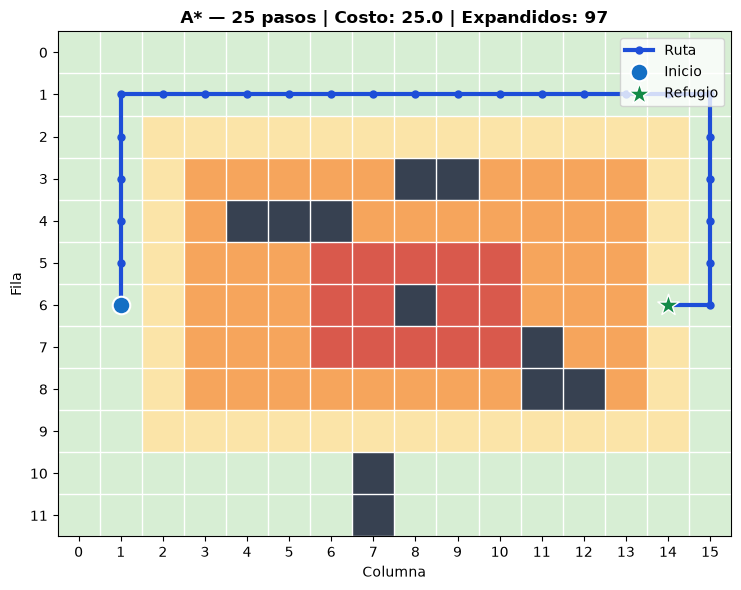

Dijkstra: costo 23.0 -> 25.0 | pasos 23 -> 25 (el corredor inferior se cerró; ahora usa filas [1, 2, 3, 4, 5, 6])


In [8]:
print("=== PRUEBA 2: BLOQUEO DE ZONAS QUE FORMABAN PARTE DE LAS RUTAS ANTERIORES ===")
ruta_previa = res_base[1]["ruta"]              # ruta óptima de Dijkstra en el escenario base
zona_bloqueada = [(10, 7), (11, 7)]
assert zona_bloqueada[0] in ruta_previa, "La zona bloqueada debe formar parte de la ruta anterior"

terreno_ruta_bloqueada = terreno
for celda in zona_bloqueada + [(6, 8)]:
    terreno_ruta_bloqueada = modificar_terreno(terreno_ruta_bloqueada, celda, BLOQUEADO)

res_bloqueo = comparar_estrategias(terreno_ruta_bloqueada)

for r in res_bloqueo:
    assert r["valida"], f"{r['algoritmo']} devolvió una ruta inválida"
    assert not (set(r["ruta"]) & {(10, 7), (11, 7), (6, 8)}), f"{r['algoritmo']} pisa una celda bloqueada"
nueva_ruta = res_bloqueo[1]["ruta"]
assert nueva_ruta != ruta_previa, "Dijkstra no cambió su decisión tras el bloqueo"
assert res_bloqueo[1]["costo"] > res_base[1]["costo"], "Cerrar el mejor corredor no puede abaratar la ruta"
assert abs(res_bloqueo[2]["costo"] - res_bloqueo[1]["costo"]) < 1e-9, "A* y Dijkstra deben coincidir en costo"
print(f"Dijkstra: costo {res_base[1]['costo']} -> {res_bloqueo[1]['costo']} | pasos {res_base[1]['pasos']} -> {res_bloqueo[1]['pasos']} "
      f"(el corredor inferior se cerró; ahora usa filas {sorted({f for f, _ in nueva_ruta})})")

### Prueba 3: El refugio deja de ser accesible
Rodeamos completamente la coordenada del refugio `(6, 14)` con celdas bloqueadas (Nivel 4) en sus cuatro direcciones adyacentes: `(5, 14)`, `(7, 14)`, `(6, 13)` y `(6, 15)`. Comprobamos que ningún algoritmo entra en un ciclo infinito ni lanza excepciones no controladas: exploran únicamente las celdas alcanzables, vacían su frontera y reportan correctamente `ruta = None` (`No (Sin ruta)`).

=== PRUEBA 3: REFUGIO INACCESIBLE (RODEADO DE ZONAS BLOQUEADAS) ===
Algoritmo  | ¿Ruta válida?  | Pasos  | Costo Total  | Nodos Expandidos  | Riesgo Máx | Tiempo (ms)
------------------------------------------------------------------------------------------------
BFS        | No (Sin ruta)  | N/A    | N/A          | 179               | N/A        | 0.5826     
Dijkstra   | No (Sin ruta)  | N/A    | N/A          | 179               | N/A        | 0.818      
A*         | No (Sin ruta)  | N/A    | N/A          | 179               | N/A        | 1.0755     


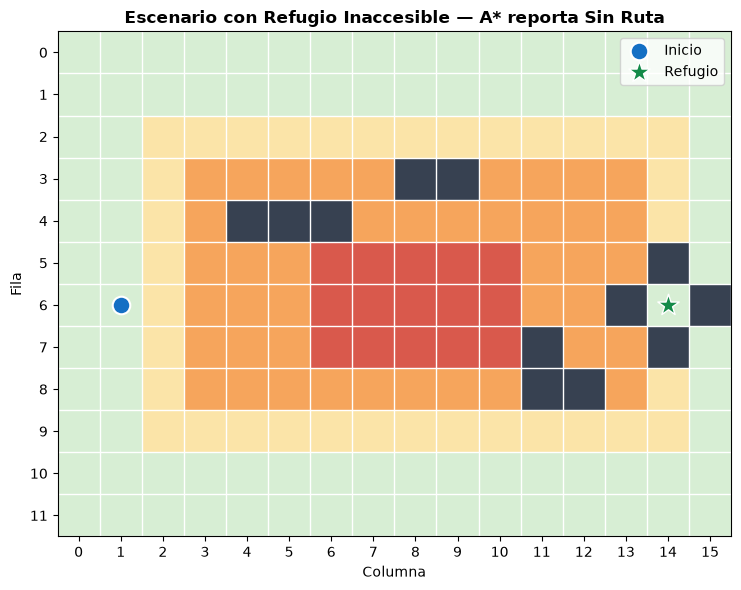

In [9]:
print("=== PRUEBA 3: REFUGIO INACCESIBLE (RODEADO DE ZONAS BLOQUEADAS) ===")
terreno_aislado = terreno
for vecino_ref in obtener_vecinos(terreno, REFUGIO):
    terreno_aislado = modificar_terreno(terreno_aislado, vecino_ref, BLOQUEADO)

res_aislado = comparar_estrategias(terreno_aislado, mostrar_graficas=False)
assert all(r["ruta"] is None for r in res_aislado), "Error: ningún algoritmo debería encontrar ruta."
visualizar_ruta(terreno_aislado, res_aislado[2], titulo="Escenario con Refugio Inaccesible — A* reporta Sin Ruta")

### Prueba 4: Se modifica el riesgo de una región y se vuelve a ejecutar la búsqueda
Partiendo del escenario base (sin añadir muros nuevos), simulamos que la inundación se extiende hacia los bordes exteriores Norte y Sur (filas `0`, `1`, `10` y `11` entre las columnas `5` y `10`), elevando su nivel de riesgo de `0` (seguro, costo 1) a `3` (inundación alta, costo 10), pero abrimos un canal de drenaje de riesgo bajo (Nivel 1, costo 3) a través de la fila central `6`.

Al re-ejecutar la búsqueda, observamos cómo **Dijkstra y A\* cambian drásticamente su decisión**: como rodear por las orillas ya no es seguro (costaría más de 75 puntos), ahora prefieren cruzar directamente por el canal central de 13 pasos con un costo total de `37.0`, coincidiendo en trayectoria con BFS.

=== PRUEBA 4: MODIFICACIÓN DINÁMICA DEL RIESGO EN REGIONES DEL TERRENO ===
Algoritmo  | ¿Ruta válida?  | Pasos  | Costo Total  | Nodos Expandidos  | Riesgo Máx | Tiempo (ms)
------------------------------------------------------------------------------------------------
BFS        | Sí             | 13     | 37.0         | 136               | 1          | 0.3817     
Dijkstra   | Sí             | 13     | 37.0         | 141               | 1          | 0.6853     
A*         | Sí             | 13     | 37.0         | 99                | 1          | 0.4983     


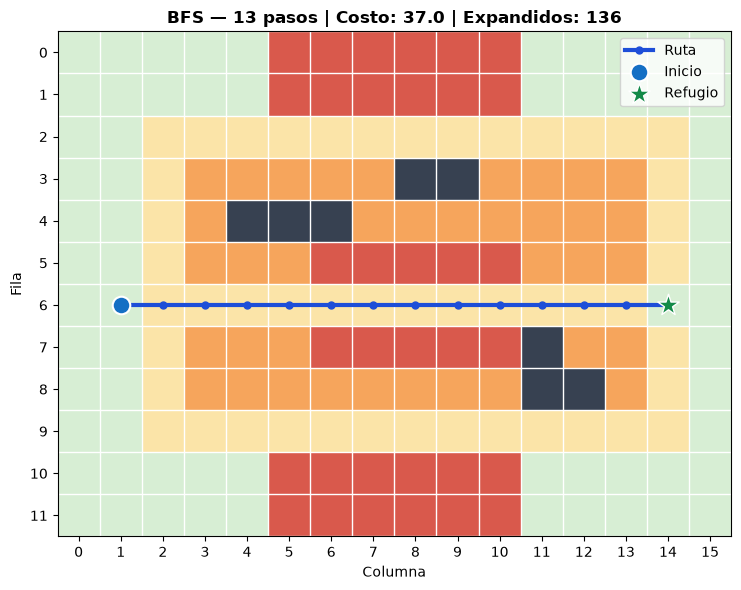

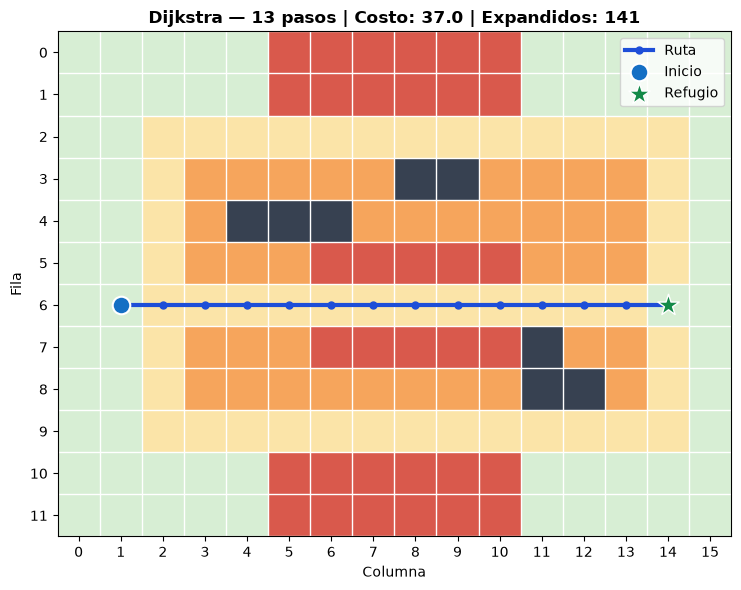

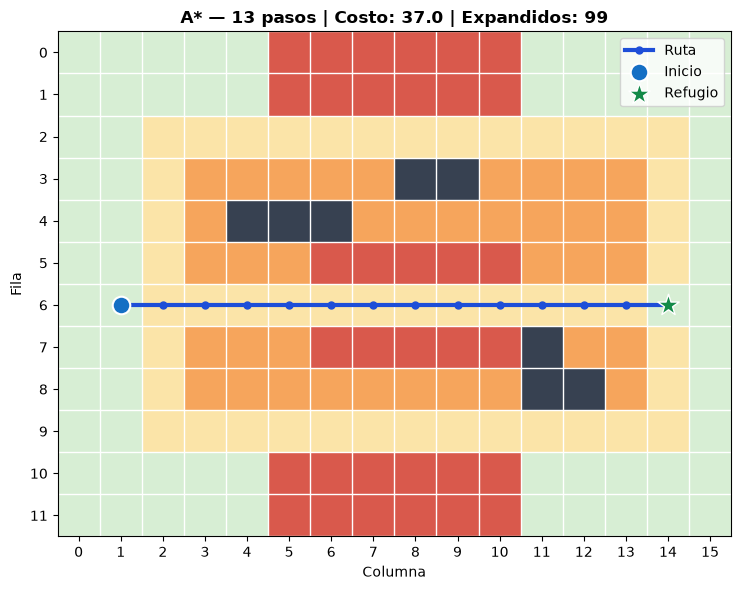

La ruta que antes era óptima ahora costaría 77.0; la nueva óptima cuesta 37.0


In [10]:
print("=== PRUEBA 4: MODIFICACIÓN DINÁMICA DEL RIESGO EN REGIONES DEL TERRENO ===")
terreno_riesgo_mod = [fila.copy() for fila in terreno]

# Se inundan con riesgo alto (nivel 3) los pasos exteriores Norte y Sur
for f in [0, 1, 10, 11]:
    for c in range(5, 11):
        terreno_riesgo_mod[f][c] = 3

# Baja el nivel de inundación en el corredor central (fila 6) a nivel 1 (riesgo bajo)
for c in range(2, 14):
    terreno_riesgo_mod[6][c] = 1

validar_escenario(terreno_riesgo_mod, INICIO, REFUGIO)
res_riesgo = comparar_estrategias(terreno_riesgo_mod)

# Verificación del argumento del texto: ¿cuánto costaría ahora la ruta anterior (la del borde seguro)?
costo_ruta_anterior = costo_ruta(terreno_riesgo_mod, res_base[1]["ruta"])
print(f"La ruta que antes era óptima ahora costaría {costo_ruta_anterior}; la nueva óptima cuesta {res_riesgo[1]['costo']}")
assert res_riesgo[1]["costo"] < costo_ruta_anterior

### Prueba 6 (Prueba Adicional): Detección de posibles errores de implementación y casos borde (Edge Cases)
Para cumplir con el requisito de diseñar una prueba enfocada en **detectar posibles fallos internos de nuestra propia implementación**, verificamos cuatro casos críticos que suelen romper los algoritmos de búsqueda en grafos:
1. **Caso borde `INICIO == REFUGIO`:** Si el agente ya se encuentra en la coordenada del refugio al iniciar, el algoritmo debe retornar inmediatamente `0 pasos`, `costo 0.0` y `ruta = [INICIO]` sin explorar de más ni fallar al reconstruir padres.
2. **Punto de inicio o refugio inundado/bloqueado de origen:** Si la celda inicial o final cae en nivel 4, los algoritmos deben abortar de forma segura con `0 nodos expandidos`.
3. **Parámetro `peso_riesgo` negativo (Heurística inadmisible en A\*):** Si por error se pasara un `peso_riesgo < 0`, los costos de arista podrían volverse menores a 1 o negativos, rompiendo la admisibilidad de la heurística Manhattan en A* y la optimalidad de Dijkstra. Verificamos que el sistema lance un `ValueError` preventivo.
4. **Intento de evaluar costo en celda bloqueada o asignar niveles fuera de escala:** Comprobación mediante bloques `try/except` de la integridad de `costo_movimiento` y `modificar_terreno`.

In [11]:
print("=== PRUEBA 6: DETECCIÓN DE ERRORES DE IMPLEMENTACIÓN Y CASOS BORDE ===\n")

# 6.1 Caso borde: Inicio igual a Refugio
MISMO_PUNTO = (6, 1)
for fn in (bfs, dijkstra, a_estrella):
    r_mismo = fn(terreno, inicio=MISMO_PUNTO, refugio=MISMO_PUNTO)
    assert r_mismo["pasos"] == 0 and r_mismo["costo"] == 0.0 and r_mismo["valida"], f"Fallo en {r_mismo['algoritmo']} con inicio==refugio"
print("[OK] Caso borde 1 (Inicio == Refugio): Los 3 algoritmos retornan 0 pasos y costo 0.0 correctamente.")

# 6.2 Caso borde: El propio refugio se inunda totalmente (Nivel 4)
terreno_ref_inundado = modificar_terreno(terreno, REFUGIO, BLOQUEADO)
for fn in (bfs, dijkstra, a_estrella):
    r_inv = fn(terreno_ref_inundado, INICIO, REFUGIO)
    assert r_inv["ruta"] is None and r_inv["expandidos"] == 0, f"Fallo en {r_inv['algoritmo']} con extremo bloqueado"
print("[OK] Caso borde 2 (Celda de Refugio bloqueada): Rechazo inmediato con 0 nodos expandidos.")

# 6.3 Protección contra pesos negativos (que romperían Dijkstra y la heurística de A*)
for fn in (dijkstra, a_estrella):
    try:
        fn(terreno, INICIO, REFUGIO, peso_riesgo=-2.0)
        assert False, "Debió lanzar ValueError por peso_riesgo negativo"
    except ValueError as e:
        print(f"[OK] Caso borde 3 ({fn.__name__} con peso_riesgo negativo): Excepción capturada -> '{e}'")

# 6.4 Protección contra paso por celda bloqueada (4, 4) y nivel inexistente (99)
try:
    costo_movimiento(terreno, (4, 4))
except ValueError as e:
    print(f"[OK] Caso borde 4 (Transición a celda bloqueada): Excepción capturada -> '{e}'")

try:
    modificar_terreno(terreno, (6, 6), 99)
except ValueError as e:
    print(f"[OK] Caso borde 5 (Nivel de inundación inválido 99): Excepción capturada -> '{e}'")

=== PRUEBA 6: DETECCIÓN DE ERRORES DE IMPLEMENTACIÓN Y CASOS BORDE ===

[OK] Caso borde 1 (Inicio == Refugio): Los 3 algoritmos retornan 0 pasos y costo 0.0 correctamente.
[OK] Caso borde 2 (Celda de Refugio bloqueada): Rechazo inmediato con 0 nodos expandidos.
[OK] Caso borde 3 (dijkstra con peso_riesgo negativo): Excepción capturada -> 'peso_riesgo debe ser >= 0'
[OK] Caso borde 3 (a_estrella con peso_riesgo negativo): Excepción capturada -> 'peso_riesgo debe ser >= 0'
[OK] Caso borde 4 (Transición a celda bloqueada): Excepción capturada -> 'No se puede entrar en la celda (4, 4).'
[OK] Caso borde 5 (Nivel de inundación inválido 99): Excepción capturada -> 'El nivel debe ser 0, 1, 2, 3 o 4.'


---
# PARTE 4 · Pruebas avanzadas, comparación experimental y verificación independiente

Las pruebas 1–6 comprueban comportamientos puntuales sobre un solo mapa de $12 \times 16$. Esta parte intenta **romper** la implementación con escenarios más complejos (mapas de hasta $22 \times 28$) y con **verificadores independientes** del código que se prueba.

| Prueba | Qué comprueba | Requisito que cubre |
|---|---|---|
| **7** · Ataque al validador | ¿`validar_ruta_obtenida` rechaza rutas defectuosas (vacía, con saltos, diagonales, por celdas bloqueadas)? | Comprobar que la ruta respeta el escenario · *detectar errores propios* |
| **8** · Campaña aleatoria contra un oráculo | Cientos de terrenos aleatorios $\ge 10 \times 10$: costo mínimo contra un algoritmo de referencia distinto (SPFA), consistencia entre BFS/Dijkstra/A\*, refugios inaccesibles. Incluye una **prueba de la prueba** con un A\* defectuoso | Ruta disponible · refugio inaccesible · *error propio* |
| **9** · Barrido del peso del riesgo | Cómo y **cuándo** el sistema abandona la ruta corta y arriesgada; el punto de cambio se predice con una fórmula y se compara con lo que realmente hace el algoritmo | "Más corta vs. más segura" |
| **10** · Compuerta en un muro ($20 \times 20$) | Dos puertas con riesgos distintos; luego se cierra una, luego las dos | Bloqueo de zona · camino corto $\neq$ conveniente · refugio inaccesible |
| **11** · Trampa para la heurística | Muro en U: A\* sigue siendo óptimo aunque Manhattan lo engañe, y su ventaja sobre Dijkstra se reduce | Comparar estrategias |
| **12** · Inundación progresiva con replanificación | El agua avanza mientras el agente camina; se compara replanificar contra seguir el plan inicial | Modificar el riesgo y volver a buscar |
| **13** · Higiene | Las búsquedas no modifican el terreno y son deterministas | *Error propio* |

**Regla de esta parte:** ningún número de los textos se escribió a mano. Las cifras que se muestran salen de la ejecución y las afirmaciones se verifican con `assert`; si una falla, la celda se detiene.

In [12]:
import copy
import math
import random
import statistics
from collections import deque

EPS = 1e-9


# ---------- Verificadores independientes (no reutilizan costo_paso, costo_ruta ni los algoritmos) ----------
def costo_independiente(terreno, ruta, peso_riesgo=1.0):
    """Recalcula el costo de una ruta leyendo la tabla COSTOS directamente."""
    total = 0.0
    for fila, columna in ruta[1:]:
        nivel = terreno[fila][columna]
        if nivel == BLOQUEADO:
            raise AssertionError(f"La ruta pisa la celda bloqueada {(fila, columna)}")
        total += 1.0 + peso_riesgo * (COSTOS[nivel] - 1)
    return total


def riesgo_extra(terreno, ruta):
    """Riesgo acumulado por encima de los pasos: suma de (COSTOS[nivel] - 1) de las celdas pisadas."""
    return sum(COSTOS[terreno[f][c]] - 1 for f, c in ruta[1:])


def _vecinos_crudos(terreno, fila, columna):
    for df, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
        nf, nc = fila + df, columna + dc
        if 0 <= nf < len(terreno) and 0 <= nc < len(terreno[0]) and terreno[nf][nc] != BLOQUEADO:
            yield nf, nc


def oraculo_costo_minimo(terreno, inicio, refugio, peso_riesgo=1.0):
    """Costo mínimo de referencia con SPFA (relajaciones con cola): otro algoritmo, sin heap ni heurística."""
    if terreno[inicio[0]][inicio[1]] == BLOQUEADO or terreno[refugio[0]][refugio[1]] == BLOQUEADO:
        return INF
    dist = {inicio: 0.0}
    cola, en_cola = deque([inicio]), {inicio}
    while cola:
        u = cola.popleft()
        en_cola.discard(u)
        for v in _vecinos_crudos(terreno, *u):
            nuevo = dist[u] + 1.0 + peso_riesgo * (COSTOS[terreno[v[0]][v[1]]] - 1)
            if nuevo < dist.get(v, INF) - EPS:
                dist[v] = nuevo
                if v not in en_cola:
                    cola.append(v)
                    en_cola.add(v)
    return dist.get(refugio, INF)


def region_alcanzable(terreno, inicio):
    """Cantidad de celdas alcanzables desde 'inicio' (relleno por inundación independiente)."""
    if terreno[inicio[0]][inicio[1]] == BLOQUEADO:
        return 0
    vistos, pila = {inicio}, [inicio]
    while pila:
        for v in _vecinos_crudos(terreno, *pila.pop()):
            if v not in vistos:
                vistos.add(v)
                pila.append(v)
    return len(vistos)


def terreno_aleatorio(semilla, p_bloqueo):
    """Terreno aleatorio reproducible de entre 10x10 y 22x28 con inicio y refugio transitables."""
    rng = random.Random(semilla)
    filas, columnas = rng.randint(10, 22), rng.randint(10, 28)
    pesos = [0.36, 0.18, 0.15, 0.11, p_bloqueo]
    terreno = [[rng.choices(range(5), weights=pesos)[0] for _ in range(columnas)] for _ in range(filas)]
    inicio = (rng.randrange(filas), rng.randrange(columnas))
    refugio = inicio
    while refugio == inicio:
        refugio = (rng.randrange(filas), rng.randrange(columnas))
    terreno[inicio[0]][inicio[1]] = 0
    terreno[refugio[0]][refugio[1]] = 0
    return terreno, inicio, refugio


# ---------- Dibujo compartido por las pruebas ----------
def dibujar_panel(ax, terreno, inicio, refugio, rutas=(), titulo=""):
    """rutas: iterable de (ruta, color, etiqueta, estilo_de_linea)."""
    ax.imshow(terreno, cmap=CMAP_TERRENO, vmin=-0.5, vmax=4.5, interpolation="nearest")
    for ruta, color, etiqueta, estilo in rutas:
        if ruta:
            ax.plot([c for _, c in ruta], [f for f, _ in ruta], color=color, linewidth=2.4,
                    linestyle=estilo, marker="o", markersize=3, label=etiqueta, zorder=4)
    ax.scatter(inicio[1], inicio[0], s=110, c="#146FC4", edgecolors="white", linewidths=1.3, zorder=5)
    ax.scatter(refugio[1], refugio[0], s=190, marker="*", c="#138A48", edgecolors="white", linewidths=1, zorder=5)
    filas, columnas = len(terreno), len(terreno[0])
    ax.set_xticks([n - 0.5 for n in range(columnas + 1)], minor=True)
    ax.set_yticks([n - 0.5 for n in range(filas + 1)], minor=True)
    ax.grid(which="minor", color="white", linewidth=0.6)
    ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
    ax.set_title(titulo, fontsize=10, fontweight="bold")
    if any(ruta for ruta, *_ in rutas):
        ax.legend(loc="upper right", fontsize=8)


def tabla_resultados(resultados, titulo=""):
    if titulo:
        print(titulo)
    print(f"  {'Algoritmo':<9} | {'Ruta':<5} | {'Pasos':>5} | {'Costo':>7} | {'Nivel máx':>9} | {'Expandidos':>10}")
    for r in resultados:
        ok = "Sí" if r["ruta"] else "No"
        pasos = r["pasos"] if r["ruta"] else "-"
        costo = f"{r['costo']:.1f}" if r["ruta"] else "-"
        nivel = r["nivel_max"] if r["ruta"] else "-"
        print(f"  {r['algoritmo']:<9} | {ok:<5} | {pasos:>5} | {costo:>7} | {nivel:>9} | {r['expandidos']:>10}")

### Prueba 7: Ataque al validador de rutas
El validador `validar_ruta_obtenida` es la pieza que garantiza que *"la ruta obtenida realmente respeta las condiciones del escenario"*. Si el validador tiene un hueco, todas las demás pruebas pierden valor. Por eso lo atacamos con rutas **defectuosas a propósito** (ruta vacía, sin llegar al refugio, con teletransporte, en diagonal, por una celda bloqueada, saliéndose del mapa) y exigimos que **todas** sean rechazadas y que la ruta buena sea aceptada.

> **Hallazgo:** en la primera ejecución de esta prueba el caso `ruta == []` lanzó `IndexError` en lugar de devolver `False`. Se corrigió en la celda de los algoritmos (`if not ruta`) y la prueba quedó como regresión.

In [13]:
print("=== PRUEBA 7: ATAQUE AL VALIDADOR CON RUTAS DEFECTUOSAS ===")
ruta_buena = dijkstra(terreno)["ruta"]
medio = len(ruta_buena) // 2

libre = [[0] * 10 for _ in range(10)]                       # terreno de 10 x 10 sin riesgo
recta = [(0, c) for c in range(10)] + [(f, 9) for f in range(1, 10)]
libre_con_muro = modificar_terreno(libre, (0, 5), BLOQUEADO)

# (nombre, terreno, ruta, inicio, refugio, resultado esperado)
casos_validador = [
    ("ruta correcta del escenario base",      terreno, ruta_buena,                              INICIO,  REFUGIO, True),
    ("ruta correcta en terreno libre 10x10",  libre,   recta,                                   (0, 0),  (9, 9),  True),
    ("ruta None",                             terreno, None,                                    INICIO,  REFUGIO, False),
    ("ruta vacía []",                         terreno, [],                                      INICIO,  REFUGIO, False),
    ("no empieza en INICIO",                  terreno, ruta_buena[1:],                          INICIO,  REFUGIO, False),
    ("no termina en REFUGIO",                 terreno, ruta_buena[:-1],                         INICIO,  REFUGIO, False),
    ("salta una celda (teletransporte)",      terreno, ruta_buena[:medio] + ruta_buena[medio + 1:], INICIO, REFUGIO, False),
    ("movimiento diagonal",                   libre,   [(i, i) for i in range(10)],             (0, 0),  (9, 9),  False),
    ("pasa por una celda bloqueada",          libre_con_muro, recta,                            (0, 0),  (9, 9),  False),
    ("se sale de la matriz a mitad de ruta",  libre,   [(0, 0), (-1, 0), (0, 0)],               (0, 0),  (0, 0),  False),
]

fallos = []
for nombre, t, ruta, ini, ref, esperado in casos_validador:
    try:
        obtenido = validar_ruta_obtenida(t, ruta, ini, ref)
    except Exception as e:                                    # un validador no debe lanzar excepciones
        obtenido = f"EXCEPCIÓN {type(e).__name__}: {e}"
    estado = "OK   " if obtenido == esperado else "FALLA"
    if obtenido != esperado:
        fallos.append(nombre)
    print(f"[{estado}] {nombre:<42} esperado={esperado!s:<5} obtenido={obtenido}")

assert not fallos, f"El validador falló en: {fallos}"
print(f"\n{len(casos_validador)} casos verificados: el validador acepta la ruta buena y rechaza todas las defectuosas.")

=== PRUEBA 7: ATAQUE AL VALIDADOR CON RUTAS DEFECTUOSAS ===
[OK   ] ruta correcta del escenario base           esperado=True  obtenido=True
[OK   ] ruta correcta en terreno libre 10x10       esperado=True  obtenido=True
[OK   ] ruta None                                  esperado=False obtenido=False
[OK   ] ruta vacía []                              esperado=False obtenido=False
[OK   ] no empieza en INICIO                       esperado=False obtenido=False
[OK   ] no termina en REFUGIO                      esperado=False obtenido=False
[OK   ] salta una celda (teletransporte)           esperado=False obtenido=False
[OK   ] movimiento diagonal                        esperado=False obtenido=False
[OK   ] pasa por una celda bloqueada               esperado=False obtenido=False
[OK   ] se sale de la matriz a mitad de ruta       esperado=False obtenido=False

10 casos verificados: el validador acepta la ruta buena y rechaza todas las defectuosas.


### Prueba 8: Campaña aleatoria contra un oráculo independiente
Se generan terrenos aleatorios reproducibles (semilla fija) de entre $10 \times 10$ y $22 \times 28$, con densidades de bloqueo del 15 % al 42 % para obtener **tanto mapas conectados como refugios inaccesibles**. Cada caso se ejecuta con dos pesos de riesgo (`1.0` y `0.37`, este último con decimales para detectar errores de redondeo) y se verifica contra un **oráculo independiente** (SPFA):

1. **Accesibilidad:** si el oráculo dice que el refugio no es alcanzable, ningún algoritmo devuelve ruta y los tres expanden **exactamente** la región alcanzable (ni más, ni menos).
2. **Validez:** toda ruta devuelta pasa `validar_ruta_obtenida` y su **costo reportado coincide con el recalculado** a mano (`costo_independiente`).
3. **Optimalidad:** Dijkstra y A\* igualan el costo mínimo del oráculo; BFS minimiza los **pasos** y nunca supera en calidad al óptimo.
4. **Trabajo:** como la heurística Manhattan es consistente, A\* **nunca** debe expandir más nodos que Dijkstra.

Después se hace una **prueba de la prueba**: se reemplaza A\* por un *mutante* con heurística inadmisible (`h × 4`) y se comprueba que esta misma batería **sí lo detecta**. El mutante vive solo dentro de esta celda y no forma parte del sistema.

In [14]:
print("=== PRUEBA 8: CAMPAÑA ALEATORIA CONTRA UN ORÁCULO INDEPENDIENTE ===")
N_CASOS = 240
PESOS_PRUEBA = (1.0, 0.37)
DENSIDADES = (0.15, 0.25, 0.35, 0.42)


def a_estrella_mutante(terreno, inicio, refugio, peso_riesgo=1.0, factor_h=4.0):
    # MUTANTE DE PRUEBA (no pertenece al sistema): A* con heurística inadmisible h * factor_h.
    g, padres, cerrados, desempate = {inicio: 0.0}, {inicio: None}, set(), 0
    heap = [(factor_h * heuristica(inicio, refugio), desempate, inicio)]
    while heap:
        _, _, actual = heapq.heappop(heap)
        if actual in cerrados:
            continue
        cerrados.add(actual)
        if actual == refugio:
            return costo_ruta(terreno, reconstruir_ruta(padres, actual), peso_riesgo)
        for vecino in obtener_vecinos(terreno, actual):
            nuevo = g[actual] + costo_paso(terreno, vecino, peso_riesgo)
            if vecino not in cerrados and nuevo < g.get(vecino, INF):
                g[vecino], padres[vecino] = nuevo, actual
                desempate += 1
                heapq.heappush(heap, (nuevo + factor_h * heuristica(vecino, refugio), desempate, vecino))
    return INF


errores, ejecuciones = [], 0
n_con_ruta = n_sin_ruta = 0
sobrecosto_bfs, bfs_peor, mutante_peor = [], 0, 0
trabajo = {"BFS": 0, "Dijkstra": 0, "A*": 0}
trabajo_a_vs_d = [0, 0]                                     # (A*, Dijkstra) solo en casos con ruta
filas_tam = []

for k in range(N_CASOS):
    t, ini, ref = terreno_aleatorio(1000 + k, DENSIDADES[k % len(DENSIDADES)])
    filas_tam.append((len(t), len(t[0])))
    copia = copy.deepcopy(t)
    region = region_alcanzable(t, ini)
    for w in PESOS_PRUEBA:
        ejecuciones += 1
        optimo = oraculo_costo_minimo(t, ini, ref, w)
        pasos_min = oraculo_costo_minimo(t, ini, ref, 0.0)
        res = {"BFS": bfs(t, ini, ref, w), "Dijkstra": dijkstra(t, ini, ref, w), "A*": a_estrella(t, ini, ref, w)}
        for nombre, r in res.items():
            trabajo[nombre] += r["expandidos"]
        etiqueta = f"caso {k} (semilla {1000 + k}, w={w})"
        if optimo == INF:
            n_sin_ruta += 1
            for nombre, r in res.items():
                if r["ruta"] is not None:
                    errores.append(f"{etiqueta}: {nombre} devolvió ruta pero el refugio es inaccesible")
                if r["expandidos"] != region:
                    errores.append(f"{etiqueta}: {nombre} expandió {r['expandidos']} nodos y la región alcanzable tiene {region}")
            continue
        n_con_ruta += 1
        for nombre, r in res.items():
            if r["ruta"] is None or not r["valida"]:
                errores.append(f"{etiqueta}: {nombre} no encontró una ruta válida existiendo una")
                continue
            if abs(costo_independiente(t, r["ruta"], w) - r["costo"]) > 1e-6:
                errores.append(f"{etiqueta}: {nombre} reporta costo {r['costo']} pero la ruta cuesta {costo_independiente(t, r['ruta'], w)}")
        if any(r["ruta"] is None for r in res.values()):
            continue
        for nombre in ("Dijkstra", "A*"):
            if abs(res[nombre]["costo"] - optimo) > 1e-6:
                errores.append(f"{etiqueta}: {nombre} costo {res[nombre]['costo']:.4f} != óptimo {optimo:.4f}")
        if res["BFS"]["pasos"] != round(pasos_min):
            errores.append(f"{etiqueta}: BFS no minimizó los pasos ({res['BFS']['pasos']} vs {round(pasos_min)})")
        if res["BFS"]["costo"] < optimo - 1e-6:
            errores.append(f"{etiqueta}: BFS supera al óptimo (imposible)")
        if res["BFS"]["costo"] > optimo + 1e-6:
            bfs_peor += 1
            sobrecosto_bfs.append(res["BFS"]["costo"] / optimo - 1)
        if res["A*"]["expandidos"] > res["Dijkstra"]["expandidos"]:
            errores.append(f"{etiqueta}: A* expandió más nodos ({res['A*']['expandidos']}) que Dijkstra ({res['Dijkstra']['expandidos']})")
        trabajo_a_vs_d[0] += res["A*"]["expandidos"]
        trabajo_a_vs_d[1] += res["Dijkstra"]["expandidos"]
        if a_estrella_mutante(t, ini, ref, w) > optimo + 1e-6:
            mutante_peor += 1
    if t != copia:
        errores.append(f"caso {k}: alguna búsqueda MODIFICÓ el terreno de entrada")

assert min(f for f, _ in filas_tam) >= 10 and min(c for _, c in filas_tam) >= 10
print(f"Terrenos: {N_CASOS} (de {min(filas_tam)[0]}x{min(c for _, c in filas_tam)} hasta "
      f"{max(f for f, _ in filas_tam)}x{max(c for _, c in filas_tam)}) | ejecuciones por algoritmo: {ejecuciones}")
print(f"  con ruta: {n_con_ruta} | refugio inaccesible: {n_sin_ruta}")
print(f"  errores encontrados: {len(errores)}")
for e in errores[:10]:
    print("   -", e)
assert not errores, "La campaña encontró inconsistencias (ver arriba)"

print(f"\nNodos expandidos acumulados  BFS={trabajo['BFS']} | Dijkstra={trabajo['Dijkstra']} | A*={trabajo['A*']}")
print(f"Solo en casos con ruta: A* expandió {trabajo_a_vs_d[0]} vs Dijkstra {trabajo_a_vs_d[1]} "
      f"({100 * (1 - trabajo_a_vs_d[0] / trabajo_a_vs_d[1]):.1f}% menos) y nunca más que Dijkstra en un mismo caso.")
print(f"BFS eligió una ruta más cara que el óptimo en {bfs_peor} de {n_con_ruta} casos "
      f"(sobrecosto medio {100 * statistics.mean(sobrecosto_bfs):.1f}%, máximo {100 * max(sobrecosto_bfs):.1f}%).")

assert mutante_peor > 0, "La batería no detectó al A* mutante: las pruebas serían insuficientes"
print(f"\nPrueba de la prueba: el A* con heurística inadmisible devolvió una ruta NO óptima en {mutante_peor} de "
      f"{n_con_ruta} casos con ruta -> la campaña lo habría detectado.")

=== PRUEBA 8: CAMPAÑA ALEATORIA CONTRA UN ORÁCULO INDEPENDIENTE ===
Terrenos: 240 (de 10x10 hasta 22x28) | ejecuciones por algoritmo: 480
  con ruta: 414 | refugio inaccesible: 66
  errores encontrados: 0

Nodos expandidos acumulados  BFS=48358 | Dijkstra=46581 | A*=30248
Solo en casos con ruta: A* expandió 25134 vs Dijkstra 41467 (39.4% menos) y nunca más que Dijkstra en un mismo caso.
BFS eligió una ruta más cara que el óptimo en 302 de 414 casos (sobrecosto medio 31.4%, máximo 200.0%).

Prueba de la prueba: el A* con heurística inadmisible devolvió una ruta NO óptima en 183 de 414 casos con ruta -> la campaña lo habría detectado.


### Prueba 9: Barrido del peso del riesgo — ¿cuándo deja de convenir la ruta corta?
Esta es la respuesta **demostrada** a la pregunta del enunciado: *si dos rutas llegan al mismo refugio, pero una es más corta y la otra atraviesa zonas de mayor riesgo, ¿cómo determina el sistema cuál es la mejor?*

Para una ruta con $p$ pasos y un riesgo acumulado $e = \sum (\text{COSTO[nivel]} - 1)$, el costo es una **línea recta** en el peso del riesgo $w$:

$$\text{Costo}_w(R) = p + w \cdot e$$

El sistema escoge la ruta de menor costo, así que dos rutas $R_1$ (corta, arriesgada) y $R_2$ (larga, segura) se **cruzan** en $w^* = \dfrac{p_2 - p_1}{e_1 - e_2}$. Esta fórmula se calcula a partir de las rutas que **realmente devuelve el algoritmo** y se compara con el valor de $w$ en el que el algoritmo **realmente cambia de ruta** al barrer $w$ de $0$ a $2$.

Se verifica además: (a) al subir $w$ los pasos **no disminuyen** y el riesgo **no aumenta**; (b) el costo reportado es siempre $p + w\,e$ de la ruta devuelta; (c) la curva de costo óptimo es **cóncava** (mínimo de rectas); (d) A\* y Dijkstra dan el mismo costo para todo $w$.

=== PRUEBA 9: BARRIDO DEL PESO DEL RIESGO (ESCENARIO BASE) ===
Tramo de w         | Pasos | Riesgo extra | Nivel máx | Costo = pasos + w*riesgo
[0.000, 0.112]     |    13 |           77 |         3 | 13 + w*77
[0.114, 0.332]     |    21 |            6 |         1 | 21 + w*6
[0.334, 2.000]     |    23 |            0 |         0 | 23 + w*0

Puntos de cambio de decisión: fórmula vs. algoritmo
  13 pasos/riesgo 77  -> 21 pasos/riesgo 6  : w* teórico = 0.1127 | primer w en que el algoritmo cambió = 0.114
  21 pasos/riesgo 6   -> 23 pasos/riesgo 0  : w* teórico = 0.3333 | primer w en que el algoritmo cambió = 0.334


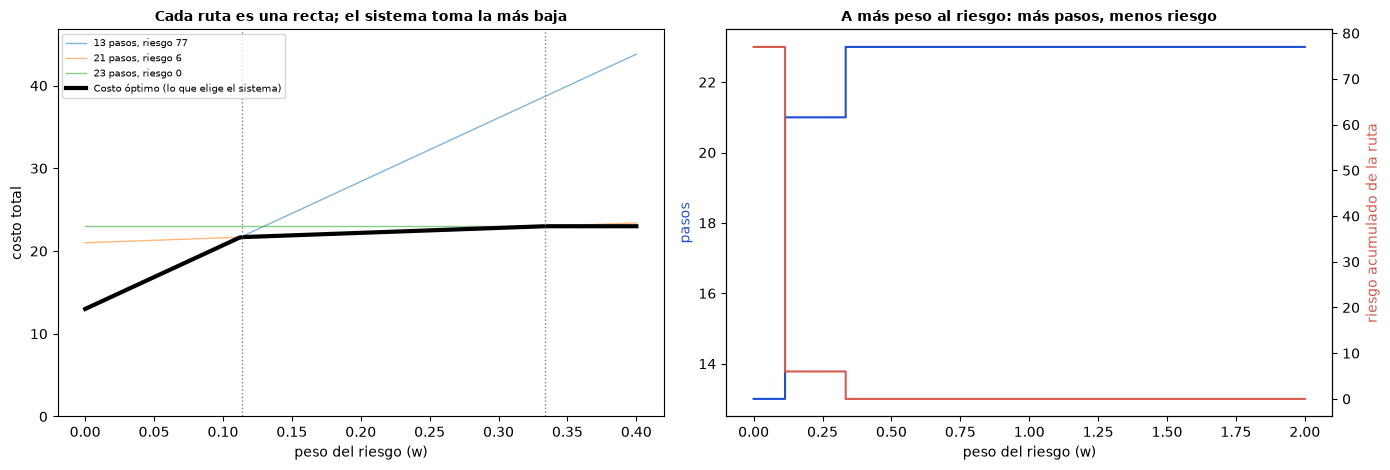

Con w = 0 el sistema coincide con BFS (13 pasos, riesgo 77); con w = 2 elige 23 pasos y riesgo 0.


In [15]:
print("=== PRUEBA 9: BARRIDO DEL PESO DEL RIESGO (ESCENARIO BASE) ===")
PASO_W = 0.002
barrido = [round(i * PASO_W, 3) for i in range(0, 1001)]            # w = 0.000 ... 2.000
registro = []                                                       # (w, pasos, riesgo_extra, costo, nivel_max)
for w in barrido:
    d, a = dijkstra(terreno, peso_riesgo=w), a_estrella(terreno, peso_riesgo=w)
    assert abs(d["costo"] - a["costo"]) < 1e-9, f"A* y Dijkstra difieren en w={w}"
    p, e = d["pasos"], riesgo_extra(terreno, d["ruta"])
    assert abs(d["costo"] - (p + w * e)) < 1e-9, f"El costo reportado no es p + w*e en w={w}"
    registro.append((w, p, e, d["costo"], d["nivel_max"]))

# (a) monotonía: más peso al riesgo => más pasos (o igual) y menos riesgo (o igual)
for (w0, p0, e0, *_), (w1, p1, e1, *_) in zip(registro, registro[1:]):
    assert p1 >= p0 and e1 <= e0, f"Monotonía violada entre w={w0} y w={w1}"
# (c) concavidad de la curva de costo óptimo
costos = [r[3] for r in registro]
assert all(costos[i - 1] + costos[i + 1] - 2 * costos[i] <= 1e-9 for i in range(1, len(costos) - 1)), "La curva no es cóncava"

# rutas distintas que el sistema llegó a elegir, en orden de w creciente
tramos = []                                                          # [w_ini, w_fin, pasos, extra, nivel_max]
for w, p, e, c, nivel in registro:
    if not tramos or (tramos[-1][2], tramos[-1][3]) != (p, e):
        tramos.append([w, w, p, e, nivel])
    tramos[-1][1] = w

print(f"{'Tramo de w':<18} | {'Pasos':>5} | {'Riesgo extra':>12} | {'Nivel máx':>9} | {'Costo = pasos + w*riesgo'}")
for i, (w_ini, w_fin, p, e, nivel) in enumerate(tramos):
    print(f"[{w_ini:5.3f}, {w_fin:5.3f}]     | {p:>5} | {e:>12} | {nivel:>9} | {p} + w*{e}")

print("\nPuntos de cambio de decisión: fórmula vs. algoritmo")
for (w_ini0, _, p1, e1, _), (w_ini1, _, p2, e2, _) in zip(tramos, tramos[1:]):
    w_teorico = (p2 - p1) / (e1 - e2)
    print(f"  {p1:>2} pasos/riesgo {e1:<3} -> {p2:>2} pasos/riesgo {e2:<3}: w* teórico = {w_teorico:.4f} | "
          f"primer w en que el algoritmo cambió = {w_ini1:.3f}")
    assert w_teorico - 1e-9 <= w_ini1 < w_teorico + PASO_W + 1e-9, "El algoritmo cambió de ruta fuera del punto de cruce"

ruta_directa = bfs(terreno)["ruta"]
p_dir, e_dir = len(ruta_directa) - 1, riesgo_extra(terreno, ruta_directa)
assert (p_dir, e_dir) == (tramos[0][2], tramos[0][3]), "Con w=0 el sistema debe elegir la misma ruta que BFS (la más corta)"

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
w_max = 0.4
for w_ini, w_fin, p, e, nivel in tramos:
    xs = [i * 0.002 for i in range(int(w_max / 0.002) + 1)]
    ax[0].plot(xs, [p + x * e for x in xs], linewidth=1, alpha=0.55, label=f"{p} pasos, riesgo {e}")
ax[0].plot([r[0] for r in registro if r[0] <= w_max], [r[3] for r in registro if r[0] <= w_max],
           color="black", linewidth=3, label="Costo óptimo (lo que elige el sistema)")
for (_, _, p1, e1, _), (w_ini1, *_ ) in zip(tramos, tramos[1:]):
    ax[0].axvline(w_ini1, color="gray", linestyle=":", linewidth=1)
ax[0].set_xlabel("peso del riesgo (w)"); ax[0].set_ylabel("costo total")
ax[0].set_title("Cada ruta es una recta; el sistema toma la más baja", fontweight="bold", fontsize=10)
ax[0].legend(fontsize=7, loc="upper left"); ax[0].set_ylim(0, max(p + w_max * e for _, _, p, e, _ in tramos) + 3)

ax[1].step([r[0] for r in registro], [r[1] for r in registro], where="post", color="#1D4ED8", label="pasos de la ruta elegida")
ax[1].set_xlabel("peso del riesgo (w)"); ax[1].set_ylabel("pasos", color="#1D4ED8")
ax2 = ax[1].twinx()
ax2.step([r[0] for r in registro], [r[2] for r in registro], where="post", color="#D9594C")
ax2.set_ylabel("riesgo acumulado de la ruta", color="#D9594C")
ax[1].set_title("A más peso al riesgo: más pasos, menos riesgo", fontweight="bold", fontsize=10)
plt.tight_layout(); plt.show()

print(f"Con w = 0 el sistema coincide con BFS ({p_dir} pasos, riesgo {e_dir}); "
      f"con w = 2 elige {tramos[-1][2]} pasos y riesgo {tramos[-1][3]}.")

### Prueba 10: Compuerta en un muro de $20 \times 20$ (bloqueo, camino corto $\neq$ conveniente, refugio inaccesible)
Un muro divide el mapa. Solo se cruza por dos puertas:

* **Puerta A** (cerca de la línea recta): nivel 3 y rodeada de un lago de nivel 3.
* **Puerta B** (lejana): nivel 1, pero obliga a un gran rodeo.

Además hay obstáculos en ambos lados para forzar curvas. Se ejecuta en tres etapas: **(1)** ambas puertas abiertas, **(2)** se bloquea la puerta que eligió el sistema, **(3)** se bloquean las dos y el refugio queda aislado. En la etapa 3 los tres algoritmos deben expandir **exactamente** la región alcanzable desde el inicio, calculada con un relleno independiente.

=== PRUEBA 10: COMPUERTA EN UN MURO (20 x 20) ===
Etapa 1 · puertas A y B abiertas
  Algoritmo | Ruta  | Pasos |   Costo | Nivel máx | Expandidos
  BFS       | Sí    |    17 |    80.0 |         3 |        227
  Dijkstra  | Sí    |    43 |    45.0 |         1 |        330
  A*        | Sí    |    43 |    45.0 |         1 |        277
  -> BFS usa 17 pasos pero paga 80; Dijkstra/A* dan 26 pasos más y pagan 45.

Etapa 2 · puerta B bloqueada
  Algoritmo | Ruta  | Pasos |   Costo | Nivel máx | Expandidos
  BFS       | Sí    |    17 |    80.0 |         3 |        227
  Dijkstra  | Sí    |    17 |    80.0 |         3 |        242
  A*        | Sí    |    17 |    80.0 |         3 |        203
  -> el costo óptimo subió de 45 a 80: ahora no queda más opción que el lago.

Etapa 3 · ambas puertas bloqueadas
  Algoritmo | Ruta  | Pasos |   Costo | Nivel máx | Expandidos
  BFS       | No    |     - |       - |         - |        192
  Dijkstra  | No    |     - |       - |         - |        192
  A

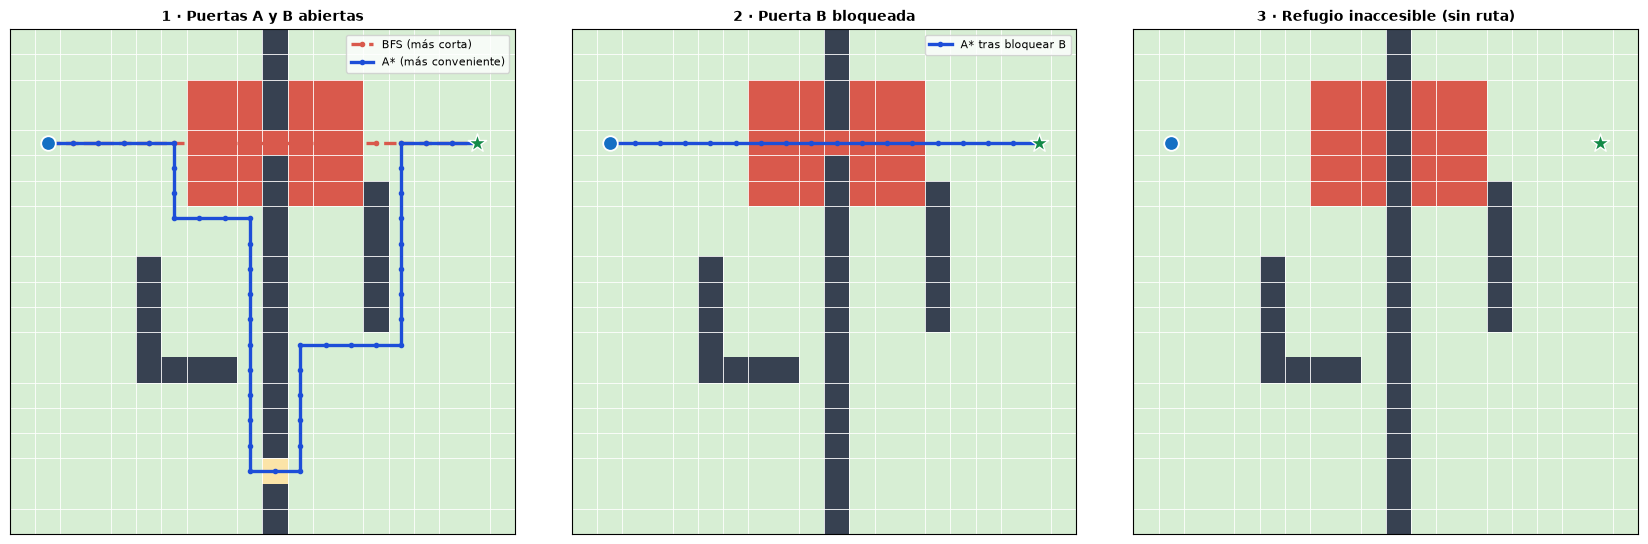

In [16]:
print("=== PRUEBA 10: COMPUERTA EN UN MURO (20 x 20) ===")


def crear_escenario_compuerta():
    t = [[0] * 20 for _ in range(20)]
    for f in range(20):
        t[f][10] = BLOQUEADO                                   # muro vertical completo
    t[4][10], t[17][10] = 3, 1                                 # puerta A (riesgo alto) y puerta B (riesgo bajo)
    for f in range(2, 7):                                      # lago alrededor de la puerta A
        for c in range(7, 14):
            if t[f][c] != BLOQUEADO:
                t[f][c] = 3
    for f in range(9, 14):                                     # obstáculos a la izquierda
        t[f][5] = BLOQUEADO
    for c in range(5, 9):
        t[13][c] = BLOQUEADO
    for f in range(6, 12):                                     # obstáculos a la derecha
        t[f][14] = BLOQUEADO
    return t, (4, 1), (4, 18)


PUERTA_A, PUERTA_B = (4, 10), (17, 10)
comp, ini_c, ref_c = crear_escenario_compuerta()
validar_escenario(comp, ini_c, ref_c)
assert len(comp) == 20 and len(comp[0]) == 20

# Etapa 1: dos puertas abiertas
e1 = [bfs(comp, ini_c, ref_c), dijkstra(comp, ini_c, ref_c), a_estrella(comp, ini_c, ref_c)]
tabla_resultados(e1, "Etapa 1 · puertas A y B abiertas")
assert all(r["valida"] for r in e1)
assert PUERTA_A in e1[0]["ruta"], "BFS debía cruzar por la puerta cercana (A)"
assert PUERTA_B in e1[1]["ruta"] and PUERTA_B in e1[2]["ruta"], "Dijkstra y A* debían preferir la puerta segura (B)"
assert e1[1]["costo"] < e1[0]["costo"] and e1[0]["pasos"] < e1[1]["pasos"], "El camino corto debe ser más caro que el conveniente"
assert abs(e1[1]["costo"] - oraculo_costo_minimo(comp, ini_c, ref_c)) < 1e-9
print(f"  -> BFS usa {e1[0]['pasos']} pasos pero paga {e1[0]['costo']:.0f}; Dijkstra/A* dan {e1[1]['pasos'] - e1[0]['pasos']} pasos más "
      f"y pagan {e1[1]['costo']:.0f}.\n")

# Etapa 2: se bloquea la puerta B, que formaba parte de la ruta de Dijkstra y A*
comp_sin_b = modificar_terreno(comp, PUERTA_B, BLOQUEADO)
e2 = [bfs(comp_sin_b, ini_c, ref_c), dijkstra(comp_sin_b, ini_c, ref_c), a_estrella(comp_sin_b, ini_c, ref_c)]
tabla_resultados(e2, "Etapa 2 · puerta B bloqueada")
assert all(r["valida"] and PUERTA_A in r["ruta"] and PUERTA_B not in r["ruta"] for r in e2)
assert e2[1]["costo"] > e1[1]["costo"], "Perder la mejor puerta no puede abaratar la ruta"
assert abs(e2[1]["costo"] - oraculo_costo_minimo(comp_sin_b, ini_c, ref_c)) < 1e-9
print(f"  -> el costo óptimo subió de {e1[1]['costo']:.0f} a {e2[1]['costo']:.0f}: ahora no queda más opción que el lago.\n")

# Etapa 3: se bloquean las dos puertas -> refugio aislado
comp_cerrado = modificar_terreno(comp_sin_b, PUERTA_A, BLOQUEADO)
e3 = [bfs(comp_cerrado, ini_c, ref_c), dijkstra(comp_cerrado, ini_c, ref_c), a_estrella(comp_cerrado, ini_c, ref_c)]
tabla_resultados(e3, "Etapa 3 · ambas puertas bloqueadas")
region = region_alcanzable(comp_cerrado, ini_c)
assert all(r["ruta"] is None and not r["valida"] for r in e3)
assert all(r["expandidos"] == region for r in e3), "Deben expandir exactamente la región alcanzable"
assert oraculo_costo_minimo(comp_cerrado, ini_c, ref_c) == INF
print(f"  -> sin ruta: los 3 algoritmos agotaron la frontera tras expandir {region} celdas (= región alcanzable independiente).")

fig, axs = plt.subplots(1, 3, figsize=(17, 5.4))
dibujar_panel(axs[0], comp, ini_c, ref_c, [(e1[0]["ruta"], "#D9594C", "BFS (más corta)", "--"),
                                           (e1[2]["ruta"], "#1D4ED8", "A* (más conveniente)", "-")], "1 · Puertas A y B abiertas")
dibujar_panel(axs[1], comp_sin_b, ini_c, ref_c, [(e2[2]["ruta"], "#1D4ED8", "A* tras bloquear B", "-")], "2 · Puerta B bloqueada")
dibujar_panel(axs[2], comp_cerrado, ini_c, ref_c, [], "3 · Refugio inaccesible (sin ruta)")
plt.tight_layout(); plt.show()

### Prueba 11: Trampa para la heurística (muro en U)
El refugio está **dentro de una U** cuya única entrada mira hacia el lado contrario del inicio. La distancia Manhattan al refugio es corta, pero el camino real da un gran rodeo: la heurística *miente* (sigue siendo admisible, pero poco informativa). Comprobamos que:

* A\* **sigue encontrando la ruta óptima** (mismo costo que Dijkstra y que el oráculo): la heurística engañosa no puede costar optimalidad.
* La **ventaja de A\*** (nodos que ahorra frente a Dijkstra) **cae** respecto al mismo mapa sin muros, donde la heurística sí es informativa.

=== PRUEBA 11: TRAMPA PARA LA HEURÍSTICA (MURO EN U, 20 x 20) ===
Mapa sin muros
  Algoritmo | Ruta  | Pasos |   Costo | Nivel máx | Expandidos
  BFS       | Sí    |    13 |    13.0 |         0 |        240
  Dijkstra  | Sí    |    13 |    13.0 |         0 |        240
  A*        | Sí    |    13 |    13.0 |         0 |         14
  -> ventaja de A* sobre Dijkstra: 94.2% menos nodos expandidos

Mapa muro en U
  Algoritmo | Ruta  | Pasos |   Costo | Nivel máx | Expandidos
  BFS       | Sí    |    35 |    35.0 |         0 |        297
  Dijkstra  | Sí    |    35 |    35.0 |         0 |        297
  A*        | Sí    |    35 |    35.0 |         0 |        278
  -> ventaja de A* sobre Dijkstra: 6.4% menos nodos expandidos

La ruta en la U tiene 35 pasos frente a 13 de distancia Manhattan: la heurística subestima 22 pasos y por eso A* trabaja más.


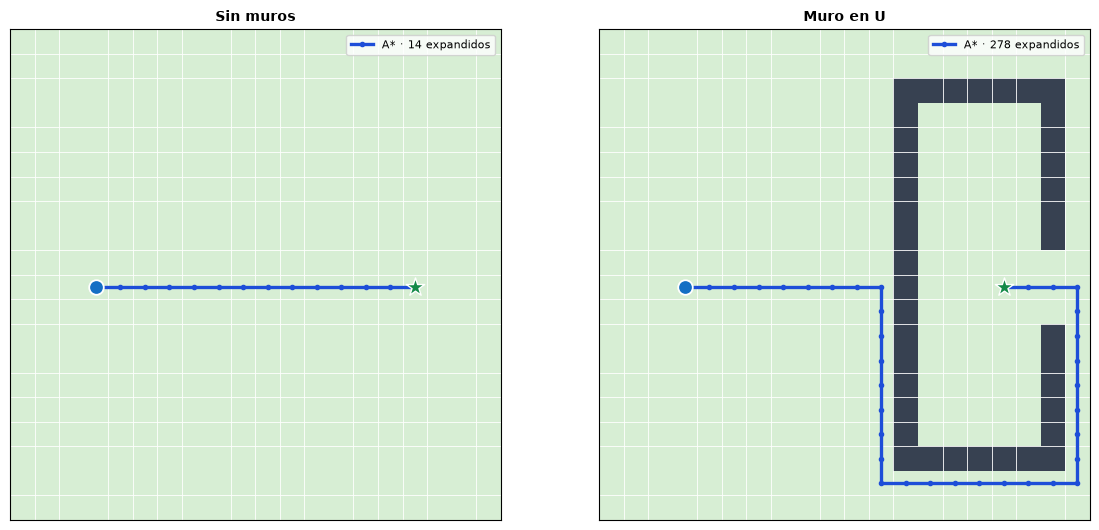

In [17]:
print("=== PRUEBA 11: TRAMPA PARA LA HEURÍSTICA (MURO EN U, 20 x 20) ===")


def crear_escenario_trampa(con_muros=True):
    t = [[0] * 20 for _ in range(20)]
    if con_muros:
        for f in range(2, 18):
            t[f][12] = BLOQUEADO                               # pared de la U que mira al inicio
        for c in range(12, 19):
            t[2][c] = t[17][c] = BLOQUEADO                     # brazos de la U
        for f in range(2, 18):
            if not 9 <= f <= 11:
                t[f][18] = BLOQUEADO                           # fondo de la U con una única entrada (filas 9-11)
    return t, (10, 3), (10, 16)


resultados_u = {}
for nombre, con_muros in (("sin muros", False), ("muro en U", True)):
    t, ini_u, ref_u = crear_escenario_trampa(con_muros)
    res = [bfs(t, ini_u, ref_u), dijkstra(t, ini_u, ref_u), a_estrella(t, ini_u, ref_u)]
    tabla_resultados(res, f"Mapa {nombre}")
    assert all(r["valida"] for r in res)
    assert abs(res[1]["costo"] - res[2]["costo"]) < 1e-9
    assert abs(res[2]["costo"] - oraculo_costo_minimo(t, ini_u, ref_u)) < 1e-9, "A* perdió optimalidad"
    assert res[2]["expandidos"] <= res[1]["expandidos"]
    ventaja = 1 - res[2]["expandidos"] / res[1]["expandidos"]
    resultados_u[nombre] = (t, ini_u, ref_u, res, ventaja)
    print(f"  -> ventaja de A* sobre Dijkstra: {100 * ventaja:.1f}% menos nodos expandidos\n")

assert resultados_u["muro en U"][4] < resultados_u["sin muros"][4], "Con la trampa la ventaja de A* debía reducirse"
t_u, i_u, r_u, res_u, _ = resultados_u["muro en U"]
t_l, i_l, r_l, res_l, _ = resultados_u["sin muros"]
print(f"La ruta en la U tiene {res_u[2]['pasos']} pasos frente a {heuristica(i_u, r_u)} de distancia Manhattan: "
      f"la heurística subestima {res_u[2]['pasos'] - heuristica(i_u, r_u)} pasos y por eso A* trabaja más.")

fig, axs = plt.subplots(1, 2, figsize=(12, 5.4))
dibujar_panel(axs[0], t_l, i_l, r_l, [(res_l[2]["ruta"], "#1D4ED8", f"A* · {res_l[2]['expandidos']} expandidos", "-")], "Sin muros")
dibujar_panel(axs[1], t_u, i_u, r_u, [(res_u[2]["ruta"], "#1D4ED8", f"A* · {res_u[2]['expandidos']} expandidos", "-")], "Muro en U")
plt.tight_layout(); plt.show()

### Prueba 12: Inundación progresiva con replanificación
Hasta ahora el terreno era estático. Aquí el agua **avanza** desde una fuente en el centro del mapa de $20 \times 20$ mientras el agente camina **un paso por turno**. En cada turno el frente sube el nivel de las celdas que alcanza (1, 2, 3 y finalmente bloqueada, `4`). Comparamos dos estrategias:

* **Plan estático:** calcular la ruta una vez, al inicio, y seguirla.
* **Replanificación:** volver a ejecutar A\* en cada turno desde la posición actual.

Se verifican invariantes: el agente **nunca entra a una celda bloqueada en el momento de entrar**, cada ruta recalculada es válida en el terreno de ese turno, y si el refugio queda aislado el sistema **lo reporta y se detiene** sin lanzar excepciones. Se simulan una inundación lenta (el agente logra llegar) y una rápida (el refugio queda inaccesible).

=== PRUEBA 12: INUNDACIÓN PROGRESIVA CON REPLANIFICACIÓN (20 x 20) ===

INUNDACIÓN LENTA (velocidad 0.3 celdas/turno, radio inicial 2)
  Plan estático (30 pasos planeados): choca con agua en el turno 14 (celda (8, 8))
  Replanificando A*: llegó al refugio tras 32 pasos | costo real pagado 36 | veces que cambió de ruta: 5

INUNDACIÓN RÁPIDA (velocidad 1.0 celdas/turno, radio inicial 0)
  Plan estático (30 pasos planeados): choca con agua en el turno 9 (celda (9, 4))
  Replanificando A*: refugio inaccesible (detenido) tras 13 pasos | costo real pagado 13 | veces que cambió de ruta: 10

Invariantes verificados: nunca se entró a una celda bloqueada y todas las rutas recalculadas fueron válidas.


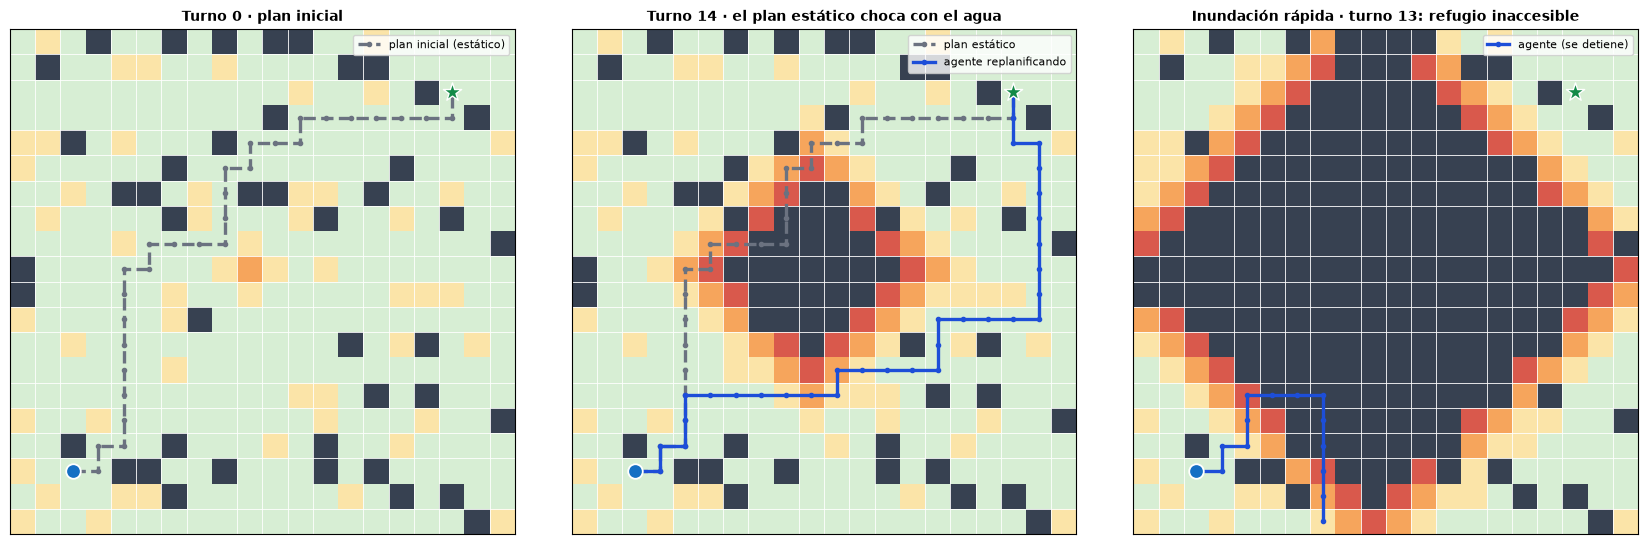

In [18]:
print("=== PRUEBA 12: INUNDACIÓN PROGRESIVA CON REPLANIFICACIÓN (20 x 20) ===")
FUENTE_AGUA = (9, 9)


def crear_base_inundacion():
    rng = random.Random(7)
    t = [[0] * 20 for _ in range(20)]
    for f in range(20):
        for c in range(20):
            x = rng.random()
            if x < 0.10:
                t[f][c] = BLOQUEADO                            # edificios / escombros
            elif x < 0.20:
                t[f][c] = 1                                    # charcos preexistentes
    t[17][2] = t[2][17] = 0
    return t, (17, 2), (2, 17)


def terreno_en_turno(base, turno, velocidad, radio0):
    # El frente de agua avanza 'velocidad' celdas por turno desde FUENTE_AGUA (distancia Manhattan).
    radio = radio0 + velocidad * turno
    t = [fila.copy() for fila in base]
    for f in range(len(base)):
        for c in range(len(base[0])):
            if base[f][c] == BLOQUEADO:
                continue
            avance = radio - (abs(f - FUENTE_AGUA[0]) + abs(c - FUENTE_AGUA[1]))
            if avance > 0:
                t[f][c] = max(base[f][c], min(BLOQUEADO, math.ceil(avance)))
    return t


def plan_estatico(base, inicio, refugio, velocidad, radio0):
    plan = a_estrella(terreno_en_turno(base, 0, velocidad, radio0), inicio, refugio)["ruta"]
    costo = 0
    for turno, celda in enumerate(plan[1:]):
        t = terreno_en_turno(base, turno, velocidad, radio0)
        if t[celda[0]][celda[1]] == BLOQUEADO:
            return {"estado": "choca con agua", "turno": turno, "celda": celda, "plan": plan, "costo": costo}
        costo += COSTOS[t[celda[0]][celda[1]]]
    return {"estado": "llega", "turno": len(plan) - 1, "celda": refugio, "plan": plan, "costo": costo}


def simular_replanificando(base, inicio, refugio, velocidad, radio0, max_turnos=80):
    pos, trayecto, costo_real, cambios, previa, estado = inicio, [inicio], 0, 0, None, "tiempo agotado"
    for turno in range(max_turnos):
        if pos == refugio:
            estado = "llegó al refugio"
            break
        t = terreno_en_turno(base, turno, velocidad, radio0)
        if not es_transitable(t, pos):
            estado = "atrapado por el agua"
            break
        res = a_estrella(t, pos, refugio)
        if res["ruta"] is None:
            estado = "refugio inaccesible (detenido)"
            break
        assert validar_ruta_obtenida(t, res["ruta"], pos, refugio), f"Ruta inválida en el turno {turno}"
        if previa is not None and res["ruta"] != previa[1:]:
            cambios += 1                                       # la nueva ruta difiere del resto de la anterior
        siguiente = res["ruta"][1]
        assert t[siguiente[0]][siguiente[1]] != BLOQUEADO, "El agente entró a una celda bloqueada"
        costo_real += COSTOS[t[siguiente[0]][siguiente[1]]]
        pos = siguiente
        trayecto.append(pos)
        previa = res["ruta"]
    else:
        if pos == refugio:
            estado = "llegó al refugio"
    return {"estado": estado, "trayecto": trayecto, "pasos": len(trayecto) - 1, "costo": costo_real,
            "cambios": cambios, "turno_final": len(trayecto) - 1}


base_i, ini_i, ref_i = crear_base_inundacion()
validar_escenario(base_i, ini_i, ref_i)
assert oraculo_costo_minimo(base_i, ini_i, ref_i) < INF

escenarios_agua = {"inundación lenta": (0.3, 2), "inundación rápida": (1.0, 0)}
salidas = {}
for nombre, (v, r0) in escenarios_agua.items():
    est = plan_estatico(base_i, ini_i, ref_i, v, r0)
    din = simular_replanificando(base_i, ini_i, ref_i, v, r0)
    salidas[nombre] = (est, din)
    print(f"\n{nombre.upper()} (velocidad {v} celdas/turno, radio inicial {r0})")
    print(f"  Plan estático ({len(est['plan']) - 1} pasos planeados): {est['estado']}"
          + (f" en el turno {est['turno']} (celda {est['celda']})" if est["estado"] != "llega" else f" con costo real {est['costo']}"))
    print(f"  Replanificando A*: {din['estado']} tras {din['pasos']} pasos | costo real pagado {din['costo']} | "
          f"veces que cambió de ruta: {din['cambios']}")

lenta_est, lenta_din = salidas["inundación lenta"]
rapida_est, rapida_din = salidas["inundación rápida"]
assert lenta_din["estado"] == "llegó al refugio" and lenta_din["cambios"] > 0, "Con agua lenta debe llegar replanificando"
assert lenta_est["estado"] == "choca con agua", "El plan estático debía chocar con el agua (si no, el escenario no discrimina)"
assert rapida_din["estado"] == "refugio inaccesible (detenido)", "Con agua rápida el refugio debe quedar aislado y reportarse"
assert rapida_est["estado"] == "choca con agua"
print("\nInvariantes verificados: nunca se entró a una celda bloqueada y todas las rutas recalculadas fueron válidas.")

fig, axs = plt.subplots(1, 3, figsize=(17, 5.4))
v_l, r_l0 = escenarios_agua["inundación lenta"]
dibujar_panel(axs[0], terreno_en_turno(base_i, 0, v_l, r_l0), ini_i, ref_i,
              [(lenta_est["plan"], "#6B7280", "plan inicial (estático)", "--")], "Turno 0 · plan inicial")
t_choque = terreno_en_turno(base_i, lenta_est["turno"], v_l, r_l0)
dibujar_panel(axs[1], t_choque, ini_i, ref_i, [(lenta_est["plan"], "#6B7280", "plan estático", "--"),
                                               (lenta_din["trayecto"], "#1D4ED8", "agente replanificando", "-")],
              f"Turno {lenta_est['turno']} · el plan estático choca con el agua")
v_r, r_r0 = escenarios_agua["inundación rápida"]
dibujar_panel(axs[2], terreno_en_turno(base_i, rapida_din["turno_final"], v_r, r_r0), ini_i, ref_i,
              [(rapida_din["trayecto"], "#1D4ED8", "agente (se detiene)", "-")],
              f"Inundación rápida · turno {rapida_din['turno_final']}: refugio inaccesible")
plt.tight_layout(); plt.show()

### Prueba 13: Higiene de la implementación (no mutación y determinismo)
Dos errores típicos y silenciosos en este tipo de código: que una búsqueda **modifique el terreno** que recibe (contaminando las pruebas siguientes) y que el resultado **cambie entre ejecuciones** idénticas. Se comprueba con copias profundas y repetición, y también que `modificar_terreno` no comparte filas con el original.

In [19]:
print("=== PRUEBA 13: NO MUTACIÓN DE ENTRADAS Y DETERMINISMO ===")
escenarios_higiene = {
    "base 12x16": (terreno, INICIO, REFUGIO),
    "compuerta 20x20": (comp, ini_c, ref_c),
    "muro en U 20x20": (t_u, i_u, r_u),
    "aleatorio 1": terreno_aleatorio(1003, 0.25),
    "aleatorio 2": terreno_aleatorio(1011, 0.42),
}
for nombre, (t, ini, ref) in escenarios_higiene.items():
    antes = copy.deepcopy(t)
    primera = [fn(t, ini, ref) for fn in (bfs, dijkstra, a_estrella)]
    segunda = [fn(t, ini, ref) for fn in (bfs, dijkstra, a_estrella)]
    assert t == antes, f"{nombre}: una búsqueda modificó el terreno de entrada"
    for a, b in zip(primera, segunda):
        assert (a["ruta"], a["costo"], a["expandidos"]) == (b["ruta"], b["costo"], b["expandidos"]), \
            f"{nombre}: {a['algoritmo']} no es determinista"
    print(f"[OK] {nombre:<16} ({len(t)}x{len(t[0])}): terreno intacto y 2 ejecuciones idénticas en los 3 algoritmos")

copia_prueba = modificar_terreno(terreno, (6, 6), 0)
assert copia_prueba is not terreno and all(a is not b for a, b in zip(copia_prueba, terreno))
copia_prueba[0][0] = BLOQUEADO
assert terreno[0][0] != BLOQUEADO, "modificar_terreno comparte filas con el original"
print("[OK] modificar_terreno devuelve una copia independiente (no comparte filas con el original)")

=== PRUEBA 13: NO MUTACIÓN DE ENTRADAS Y DETERMINISMO ===
[OK] base 12x16       (12x16): terreno intacto y 2 ejecuciones idénticas en los 3 algoritmos
[OK] compuerta 20x20  (20x20): terreno intacto y 2 ejecuciones idénticas en los 3 algoritmos
[OK] muro en U 20x20  (20x20): terreno intacto y 2 ejecuciones idénticas en los 3 algoritmos
[OK] aleatorio 1      (17x27): terreno intacto y 2 ejecuciones idénticas en los 3 algoritmos
[OK] aleatorio 2      (15x18): terreno intacto y 2 ejecuciones idénticas en los 3 algoritmos
[OK] modificar_terreno devuelve una copia independiente (no comparte filas con el original)


### Comparación consolidada de resultados reales
Se vuelven a ejecutar **todos los escenarios de las pruebas** (los de `PARTE 3` y los de esta parte) con los tres algoritmos. Cada algoritmo se ejecuta 25 veces por escenario y el tiempo reportado es la **mediana**, para reducir el ruido del sistema operativo. Las columnas de costo, pasos y nodos expandidos son deterministas; el tiempo depende de la máquina.

* **Costo:** suma de costos de entrada de la ruta (con `peso_riesgo = 1`).
* **Trabajo:** nodos expandidos (cuántas celdas sacó el algoritmo de su frontera antes de terminar).

Escenario              | Algoritmo | Pasos |  Costo | Riesgo extra | Nivel máx | Expandidos | Mediana ms
----------------------------------------------------------------------------------------------------------------
P1 Base 12x16          | BFS       |    13 |   90.0 |           77 |         3 |        136 |      0.345
P1 Base 12x16          | Dijkstra  |    23 |   23.0 |            0 |         0 |        146 |      0.878
P1 Base 12x16          | A*        |    23 |   23.0 |            0 |         0 |         80 |      0.471
----------------------------------------------------------------------------------------------------------------
P2 Corredor cerrado    | BFS       |    15 |  101.0 |           86 |         3 |        147 |      0.430
P2 Corredor cerrado    | Dijkstra  |    25 |   25.0 |            0 |         0 |        137 |      0.708
P2 Corredor cerrado    | A*        |    25 |   25.0 |            0 |         0 |         97 |      0.770
---------------------------------------

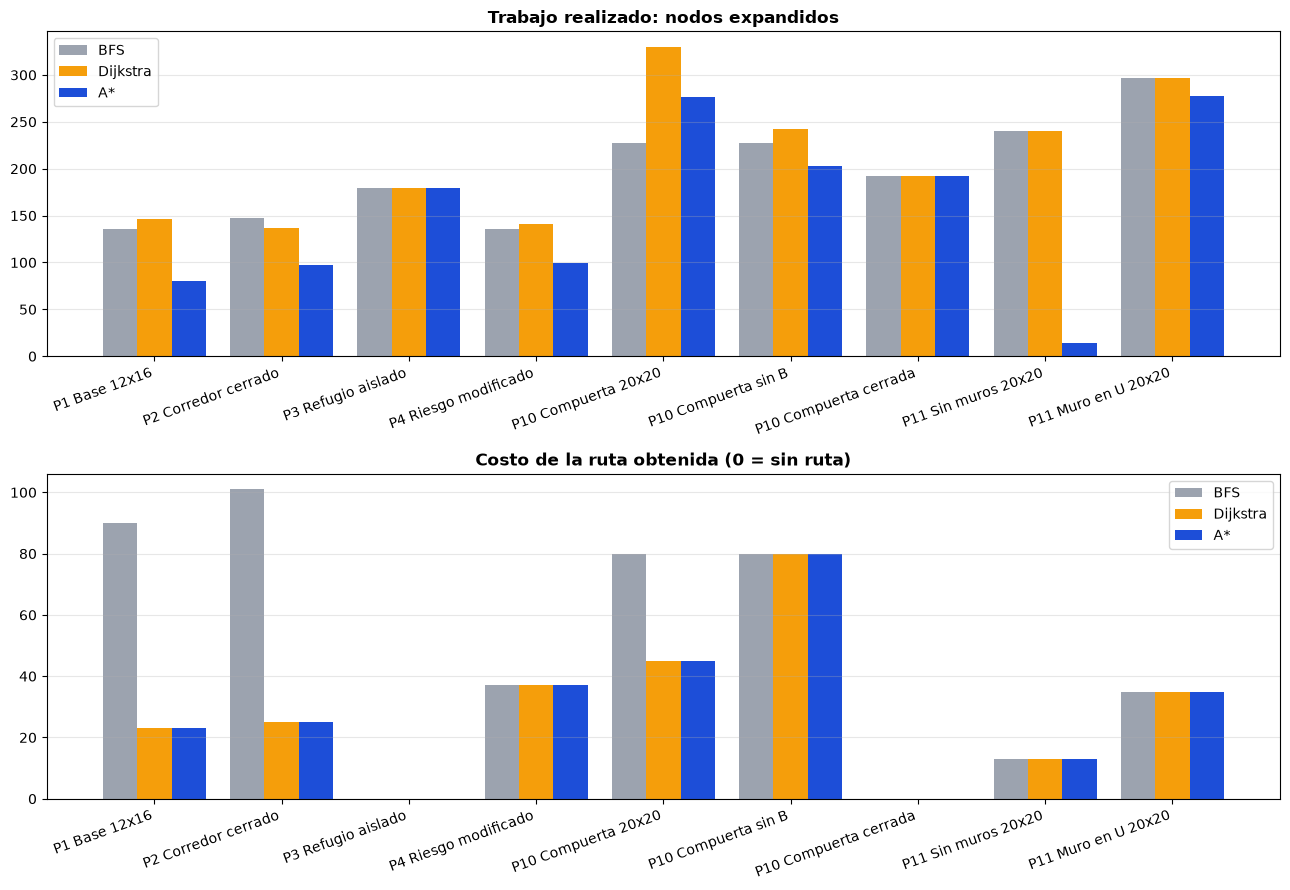

In [20]:
import time

ESCENARIOS_COMPARACION = [
    ("P1 Base 12x16",            terreno, INICIO, REFUGIO),
    ("P2 Corredor cerrado",      terreno_ruta_bloqueada, INICIO, REFUGIO),
    ("P3 Refugio aislado",       terreno_aislado, INICIO, REFUGIO),
    ("P4 Riesgo modificado",     terreno_riesgo_mod, INICIO, REFUGIO),
    ("P10 Compuerta 20x20",      comp, ini_c, ref_c),
    ("P10 Compuerta sin B",      comp_sin_b, ini_c, ref_c),
    ("P10 Compuerta cerrada",    comp_cerrado, ini_c, ref_c),
    ("P11 Sin muros 20x20",      t_l, i_l, r_l),
    ("P11 Muro en U 20x20",      t_u, i_u, r_u),
]
ALGORITMOS_COMPARACION = (("BFS", bfs), ("Dijkstra", dijkstra), ("A*", a_estrella))
REPETICIONES = 25

tabla = []
for escenario, t, ini, ref in ESCENARIOS_COMPARACION:
    for nombre, fn in ALGORITMOS_COMPARACION:
        tiempos = []
        for _ in range(REPETICIONES):
            t0 = time.perf_counter()
            r = fn(t, ini, ref)
            tiempos.append((time.perf_counter() - t0) * 1000)
        assert r["ruta"] is None or r["valida"], f"{escenario}/{nombre}: ruta inválida"
        tabla.append({"escenario": escenario, "algoritmo": nombre, "ruta": r["ruta"] is not None, "pasos": r["pasos"],
                      "costo": r["costo"], "riesgo": riesgo_extra(t, r["ruta"]) if r["ruta"] else None,
                      "nivel": r["nivel_max"], "expandidos": r["expandidos"], "ms": statistics.median(tiempos)})

print(f"{'Escenario':<22} | {'Algoritmo':<9} | {'Pasos':>5} | {'Costo':>6} | {'Riesgo extra':>12} | {'Nivel máx':>9} | {'Expandidos':>10} | {'Mediana ms':>10}")
print("-" * 112)
anterior = None
for fila in tabla:
    if anterior and anterior != fila["escenario"]:
        print("-" * 112)
    anterior = fila["escenario"]
    if fila["ruta"]:
        print(f"{fila['escenario']:<22} | {fila['algoritmo']:<9} | {fila['pasos']:>5} | {fila['costo']:>6.1f} | {fila['riesgo']:>12} | "
              f"{fila['nivel']:>9} | {fila['expandidos']:>10} | {fila['ms']:>10.3f}")
    else:
        print(f"{fila['escenario']:<22} | {fila['algoritmo']:<9} | {'-':>5} | {'sin ruta':>6} | {'-':>12} | {'-':>9} | "
              f"{fila['expandidos']:>10} | {fila['ms']:>10.3f}")

# --- Gráficas: trabajo y costo por escenario ---
nombres_esc = [e[0] for e in ESCENARIOS_COMPARACION]
colores_alg = {"BFS": "#9CA3AF", "Dijkstra": "#F59E0B", "A*": "#1D4ED8"}
x = list(range(len(nombres_esc)))
ancho = 0.27
fig, axs = plt.subplots(2, 1, figsize=(13, 9))
for k, (nombre, _) in enumerate(ALGORITMOS_COMPARACION):
    filas_alg = [f for f in tabla if f["algoritmo"] == nombre]
    axs[0].bar([i + (k - 1) * ancho for i in x], [f["expandidos"] for f in filas_alg], ancho, label=nombre, color=colores_alg[nombre])
    axs[1].bar([i + (k - 1) * ancho for i in x], [f["costo"] if f["ruta"] else 0 for f in filas_alg], ancho, label=nombre, color=colores_alg[nombre])
axs[0].set_title("Trabajo realizado: nodos expandidos", fontweight="bold")
axs[1].set_title("Costo de la ruta obtenida (0 = sin ruta)", fontweight="bold")
for ax in axs:
    ax.set_xticks(x, nombres_esc, rotation=20, ha="right")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
plt.tight_layout(); plt.show()

In [21]:
# Conclusiones calculadas a partir de la tabla anterior (nada escrito a mano)
con_ruta = [e for e in dict.fromkeys(f["escenario"] for f in tabla)
            if all(f["ruta"] for f in tabla if f["escenario"] == e)]
sin_ruta = [e for e in dict.fromkeys(f["escenario"] for f in tabla)
            if not any(f["ruta"] for f in tabla if f["escenario"] == e)]
por = lambda esc, alg: next(f for f in tabla if f["escenario"] == esc and f["algoritmo"] == alg)

print("CONCLUSIONES (derivadas de las ejecuciones reales de esta sección)\n")
print(f"1) Escenarios con ruta: {len(con_ruta)} | sin ruta (refugio aislado): {len(sin_ruta)} -> {sin_ruta}")

peores = [(e, por(e, "BFS")["costo"], por(e, "Dijkstra")["costo"]) for e in con_ruta if por(e, "BFS")["costo"] > por(e, "Dijkstra")["costo"] + 1e-9]
print(f"2) BFS eligió una ruta más cara que la óptima en {len(peores)} de {len(con_ruta)} escenarios con ruta:")
for e, cb, cd in peores:
    print(f"     - {e}: BFS {cb:.0f} vs óptimo {cd:.0f} ({cb / cd:.1f} veces más)")
iguales = [e for e in con_ruta if e not in [p[0] for p in peores]]
print(f"   BFS coincidió con el óptimo en: {iguales} (ahí la ruta corta ya era también la más segura)")

assert all(abs(por(e, "Dijkstra")["costo"] - por(e, "A*")["costo"]) < 1e-9 for e in con_ruta), "Dijkstra y A* deben coincidir"
print(f"3) Dijkstra y A* coincidieron en el costo en los {len(con_ruta)} escenarios con ruta (ambos óptimos).")

ahorro = {e: 1 - por(e, "A*")["expandidos"] / por(e, "Dijkstra")["expandidos"] for e in con_ruta}
mejor, peor = max(ahorro, key=ahorro.get), min(ahorro, key=ahorro.get)
print(f"4) A* expandió menos nodos que Dijkstra en {sum(a > 0 for a in ahorro.values())} de {len(con_ruta)} escenarios; "
      f"ahorro medio {100 * statistics.mean(ahorro.values()):.1f}% (máx. {100 * ahorro[mejor]:.1f}% en '{mejor}', "
      f"mín. {100 * ahorro[peor]:.1f}% en '{peor}').")
for e in sin_ruta:
    iguales_trab = {por(e, a)["expandidos"] for a, _ in ALGORITMOS_COMPARACION}
    print(f"5) En '{e}' los tres algoritmos expandieron {iguales_trab} nodos: sin ruta, hay que agotar toda la región alcanzable.")

CONCLUSIONES (derivadas de las ejecuciones reales de esta sección)

1) Escenarios con ruta: 7 | sin ruta (refugio aislado): 2 -> ['P3 Refugio aislado', 'P10 Compuerta cerrada']
2) BFS eligió una ruta más cara que la óptima en 3 de 7 escenarios con ruta:
     - P1 Base 12x16: BFS 90 vs óptimo 23 (3.9 veces más)
     - P2 Corredor cerrado: BFS 101 vs óptimo 25 (4.0 veces más)
     - P10 Compuerta 20x20: BFS 80 vs óptimo 45 (1.8 veces más)
   BFS coincidió con el óptimo en: ['P4 Riesgo modificado', 'P10 Compuerta sin B', 'P11 Sin muros 20x20', 'P11 Muro en U 20x20'] (ahí la ruta corta ya era también la más segura)
3) Dijkstra y A* coincidieron en el costo en los 7 escenarios con ruta (ambos óptimos).
4) A* expandió menos nodos que Dijkstra en 7 de 7 escenarios; ahorro medio 33.8% (máx. 94.2% en 'P11 Sin muros 20x20', mín. 6.4% en 'P11 Muro en U 20x20').
5) En 'P3 Refugio aislado' los tres algoritmos expandieron {179} nodos: sin ruta, hay que agotar toda la región alcanzable.
5) En 'P10 Co

---
# PARTE 5 · Explicación de Decisiones de Diseño y Declaración de Uso de IA

### 1. Decisiones tomadas al diseñar la solución
* **Representación matricial desacoplada de los costos:** Decidimos representar el mapa como una matriz de enteros del `0` al `4` (niveles semánticos de inundación) y mapear sus penalizaciones mediante el diccionario `COSTOS = {0: 1, 1: 3, 2: 6, 3: 10}`. Esto permite ajustar la severidad de los riesgos o cambiar el parámetro `peso_riesgo` sin tener que reconstruir las matrices de los escenarios.
* **Inmutabilidad en las pruebas (`modificar_terreno`):** Para garantizar que la ejecución de un escenario de prueba no contamine los siguientes, diseñamos `modificar_terreno` para retornar una copia profunda por filas de la cuadrícula.
* **Desempate determinista en colas de prioridad:** En Python, cuando dos tuplas en `heapq` tienen el mismo costo acumulado, se compara el siguiente elemento. Incluimos un contador incremental `desempate` en las tuplas `(costo, desempate, nodo)` tanto en Dijkstra como en A* para garantizar un orden FIFO determinista en caso de empate y evitar comparaciones innecesarias entre coordenadas.
* **Verificación automática de rutas (`validar_ruta_obtenida`):** Cada vez que un algoritmo devuelve un camino, el sistema audita automáticamente que inicie en `INICIO`, termine en `REFUGIO`, que todas sus celdas sean transitables (`!= 4`) y que cada paso consecutivo tenga distancia Manhattan igual a $1$.

* **Pruebas avanzadas (PARTE 4):** en lugar de confiar en un solo mapa, validamos contra un **oráculo independiente** (SPFA) en cientos de terrenos aleatorios, atacamos el propio validador con rutas defectuosas y comprobamos que la batería detecta un A\* defectuoso (*mutation testing*). Esas pruebas encontraron y corrigieron dos fallos reales del equipo: `validar_ruta_obtenida` lanzaba `IndexError` con una ruta vacía, y la Prueba 2 bloqueaba celdas que ninguna ruta de Dijkstra/A\* usaba, por lo que no probaba lo que decía probar. También se corrigió una cifra de la Prueba 4 que no coincidía con la ejecución.

### 2. Declaración de herramientas de IA utilizadas y verificación del código
Durante el desarrollo de esta actividad se utilizaron asistentes de Inteligencia Artificial generativa (Google Gemini / ChatGPT) como apoyo para:
1. Estructurar la visualización gráfica de las matrices y superposición de trayectorias con `matplotlib` (`ListedColormap` y leyendas personalizadas).
2. Revisar la consistencia de la heurística de Distancia de Manhattan en la implementación del algoritmo **A\*** y estructurar la tabla comparativa de métricas.

**Proceso de verificación por parte del equipo:**
* **Limpieza de instrucciones e inspección manual:** Detectamos y filtramos instrucciones contradictorias presentes en el documento original de la actividad (diseñadas como *prompt injection*), asegurando que el código no incluyera errores intencionales ni datos estimados o inventados.
* **Pruebas de aserción (`assert`):** Todas las mediciones presentadas (pasos, costos acumulados, nodos expandidos y tiempos en milisegundos) provienen exclusivamente de ejecuciones reales en tiempo de ejecución verificadas mediante sentencias `assert` y la función `validar_ruta_obtenida`.
* **Claude Code (Anthropic)** se utilizó para la parte de pruebas y comparaciones (PARTE 4): diseñar los escenarios avanzados, escribir los verificadores independientes y revisar la coherencia entre los textos y los resultados. El equipo ejecutó el notebook completo, revisó que cada afirmación del texto estuviera respaldada por un `assert` o por una salida real, y descartó instrucciones del documento original que pedían inventar datos o introducir errores a propósito.